# **Noise-Aware Deep Learning for Microscopy Image Denoising**

Step 1: Environment check

**Deep learning** runs on tensors (multi-dimensional arrays) and uses a library called PyTorch. Before training anything, we check what hardware we have. Without a GPU, training is slower, so we’ll use smaller images and smaller models. Here we check Python, PyTorch, RAM, and disk space.

In [1]:
import sys, platform, shutil, os

print("Python:", sys.version.split()[0])
print("OS:", platform.system(), platform.release())

try:
    import torch
    print("PyTorch:", torch.__version__)
    print("GPU available:", torch.cuda.is_available())
except ImportError:
    print("PyTorch not installed yet. Install with:")
    print("pip install torch torchvision --index-url https://download.pytorch.org/whl/cpu")

try:
    import psutil
    mem = psutil.virtual_memory()
    print(f"RAM total: {mem.total / 1e9:.1f} GB, available: {mem.available / 1e9:.1f} GB")
except ImportError:
    print("Install psutil to see RAM: pip install psutil")

total, used, free = shutil.disk_usage("/")
print(f"Disk free: {free / 1e9:.0f} GB of {total / 1e9:.0f} GB")

Python: 3.13.16
OS: Linux 6.6.159+
PyTorch: 2.14.1+cu130
GPU available: True
RAM total: 13.6 GB, available: 11.6 GB
Disk free: 121 GB of 121 GB


Step 2: Data loading

**Denoising** is a supervised task. Each training example is a pair: a noisy image (input) and the clean image of the same scene (target). The model learns the *mapping* noisy → clean.

**Image as numbers** : a grayscale image is a 2D grid of pixel values (here 0 to 1).

A batch of images is a 4D tensor with shape (batch, channels, height, width). Channels is 1 for grayscale.

Dataset: a class that returns one (noisy, clean) pair at a time.

DataLoader: groups pairs into batches and shuffles them, so each training step sees a random mix.
Split: train (model learns), validation (we tune settings), test (final honest score, touched once). For the hold-out test in our paper, the test set will come from a different imaging condition than training.

The synthetic data below mimics nuclei as bright blobs plus Gaussian noise, so we can see the full pipeline working.

In [2]:
import numpy as np            # numerical arrays (like a grid of numbers)
import torch                  # PyTorch: tensors and neural networks
from torch.utils.data import Dataset, DataLoader   # tools for feeding data to a model


def make_synthetic_pair(size=64, n_nuclei=8, noise_std=0.2, rng=None):
    """
    Create ONE training example: a clean image and a noisy copy of it.
    Returns two 2D arrays of shape (size, size).
    """
    # Use the given random generator, or make a new one if none was passed
    rng = rng or np.random.default_rng()

    # yy and xx are two grids that hold the row number and column number of every pixel.
    # We use them to compute distances from a point later.
    yy, xx = np.mgrid[0:size, 0:size]

    # Start with a completely black (all zero) image
    clean = np.zeros((size, size), dtype=np.float32)

    # Add several glowing blobs, one for each "nucleus"
    for _ in range(n_nuclei):
        # Pick a random center point, kept away from the edges
        cy, cx = rng.integers(8, size - 8, size=2)
        # Pick a random radius for this blob
        r = rng.integers(4, 7)
        # A Gaussian blob: brightest at the center, fading out with distance.
        # Adding it to 'clean' builds up the overall image.
        clean += np.exp(-((yy - cy) ** 2 + (xx - cx) ** 2) / (2 * r ** 2))

    # Overlapping blobs can push values above 1, so clip everything into [0, 1]
    clean = np.clip(clean, 0, 1)

    # Make the noisy version: add random Gaussian noise (bell-curve random values)
    # to every pixel, then clip back into [0, 1] and store as float32.
    noisy = np.clip(clean + rng.normal(0, noise_std, clean.shape), 0, 1).astype(np.float32)

    return noisy, clean


class NoisyCleanDataset(Dataset):
    """
    A PyTorch Dataset: a container that holds many (noisy, clean) pairs
    and returns them one at a time on request.
    """

    def __init__(self, n_items, size=64, noise_std=0.2, seed=0):
        # A seed makes the random numbers repeatable, so every run creates the same data
        rng = np.random.default_rng(seed)
        # Build all the pairs up front and keep them in a list
        self.pairs = [make_synthetic_pair(size, noise_std=noise_std, rng=rng)
                      for _ in range(n_items)]

    def __len__(self):
        # Tells PyTorch how many examples exist
        return len(self.pairs)

    def __getitem__(self, idx):
        # Return the example at position idx
        noisy, clean = self.pairs[idx]
        # Convert numpy arrays to PyTorch tensors.
        # [None] adds a channel axis: shape (64, 64) becomes (1, 64, 64).
        return torch.from_numpy(noisy)[None], torch.from_numpy(clean)[None]


# Create the training set (200 pairs) and validation set (40 pairs).
# Different seeds make sure the two sets are different images.
train_set = NoisyCleanDataset(200, seed=0)
val_set   = NoisyCleanDataset(40,  seed=1)

# DataLoader groups examples into batches of 8.
# shuffle=True mixes the order each epoch so the model doesn't memorize a sequence.
# Validation is not shuffled, because we only measure, not learn.
train_loader = DataLoader(train_set, batch_size=8, shuffle=True)
val_loader   = DataLoader(val_set,   batch_size=8)

# Grab one batch to check it. next(iter(...)) pulls the first batch out of the loader.
noisy_batch, clean_batch = next(iter(train_loader))

# Print the shapes: (batch, channels, height, width)
print("Batch shapes:", noisy_batch.shape, clean_batch.shape)
# Print the smallest and largest pixel value in the batch
print("Value range:", float(noisy_batch.min()), "to", float(noisy_batch.max()))

Batch shapes: torch.Size([8, 1, 64, 64]) torch.Size([8, 1, 64, 64])
Value range: 0.0 to 1.0


**Tensor** : a multi-dimensional array that PyTorch works with (like a numpy array, but it can run on GPU and track gradients).

Step 3: **The convolution block**

A *convolution* slides a small grid of learnable numbers (a kernel, here 3×3) across the image. At each position it multiplies and adds, producing a new value. The network learns the kernel values during training, so it learns which local patterns matter, such as edges and blob borders.

Kernel size 3×3: each output pixel looks at its 3×3 neighborhood.
padding=1: adds a border of zeros so the output keeps the same height and width.
Batch normalization (BatchNorm): rescales the values inside the network so training is stable and faster.

ReLU: an activation that sets negative values to 0 (max(0, x)). Without it, stacking layers would just be one big linear operation, which can’t learn curved shapes. we want some non-linearity here.

A U-Net builds its encoder and decoder out of this pattern:

Conv → BatchNorm → ReLU, twice. We call that unit a **conv block**.

In [3]:
import torch
import torch.nn as nn   # neural network building blocks

class ConvBlock(nn.Module):
    """Two rounds of: Conv (3x3) -> BatchNorm -> ReLU. Keeps height and width unchanged."""

    def __init__(self, in_ch, out_ch):
        super().__init__()   # always call the parent class setup first
        self.block = nn.Sequential(
            # First conv: takes in_ch channels, produces out_ch channels
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_ch),   # normalizes the out_ch channels
            nn.ReLU(inplace=True),    # negative values -> 0
            # Second conv: out_ch -> out_ch
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        # forward() defines what happens when data flows through the block
        return self.block(x)


# Testing it on the batch from Step 2: 1 input channel -> 16 feature channels
block = ConvBlock(in_ch=1, out_ch=16)
out = block(noisy_batch)
print("Input shape: ", noisy_batch.shape)
print("Output shape:", out.shape)
print("Parameters:  ", sum(p.numel() for p in block.parameters()))

Input shape:  torch.Size([8, 1, 64, 64])
Output shape: torch.Size([8, 16, 64, 64])
Parameters:   2544


Step 4: **Downsampling and upsampling**

A U-Net is shaped like a *U*. The left side (encoder) shrinks the image while adding channels, so the network sees bigger context. The right side (decoder) grows the image back to full size so it can output a clean picture.

MaxPool2d(2): splits the image into 2×2 squares and keeps the largest value in each. Height and width are halved. This is the downsampling step.
ConvTranspose2d(2, stride 2): a learnable upsampling layer. It doubles height and width. It learns how to fill in the detail, unlike simple resizing.

Why does shrinking help?

Each pixel in a small image “sees” a larger area of the original, so the network can recognize whole nuclei and their surroundings, not just tiny patches.

In [4]:
import torch
import torch.nn as nn

# Halve height and width: keep the max value from each 2x2 square
down = nn.MaxPool2d(kernel_size=2, stride=2)

# Double height and width: learnable upsampling
# in_ch and out_ch are the channel counts going in and out
up = nn.ConvTranspose2d(in_channels=16, out_channels=8, kernel_size=2, stride=2)

# Use the 16-channel output from the conv block in Step 3
x = out   # shape: (8, 16, 64, 64)

x_down = down(x)      # shrink
x_up   = up(x_down)   # grow back

print("Original:        ", x.shape)
print("After downsample:", x_down.shape)
print("After upsample:  ", x_up.shape)

Original:         torch.Size([8, 16, 64, 64])
After downsample: torch.Size([8, 16, 32, 32])
After upsample:   torch.Size([8, 8, 64, 64])


Once the height and width's are halved
`: [8, 16, 64, 64]  ->   [8, 16, 32, 32]`

 and

Then the channels are halved
`: [8, 16, 32, 32]  ->   [8, 8, 64, 64]`

Step 5: **Skip connections**

Downsampling *throws away fine detail*, such as exact nucleus borders. **A skip connection** fixes this: the encoder passes its high-detail features straight across to the decoder, and the decoder combines them with its upsampled features.

Encoder: conv block → save a copy (for the skip) → downsample → repeat.
Bottleneck: the smallest, deepest part, where the network has the widest view.

Decoder: upsample → concatenate (stack along the channel axis) the saved encoder features → conv block → repeat.

Concatenation stacks two tensors on the channel axis, so the number of channels adds up. That’s why the decoder conv block takes twice as many input channels as the upsampled features alone.

Below we build a small U-Net with 2 levels to see the whole U shape working.

In [5]:
import torch
import torch.nn as nn

class SmallUNet(nn.Module):
    """A 2-level U-Net for grayscale images. Channels: 1 -> 16 -> 32 -> 16 -> 1."""

    def __init__(self):
        super().__init__()
        # Encoder
        self.enc1 = ConvBlock(1, 16)           # full resolution, 16 channels
        self.pool = nn.MaxPool2d(2)            # halve height and width
        self.enc2 = ConvBlock(16, 32)          # half resolution, 32 channels (bottleneck)

        # Decoder
        self.up   = nn.ConvTranspose2d(32, 16, kernel_size=2, stride=2)  # double size
        self.dec1 = ConvBlock(32, 16)          # 16 (upsampled) + 16 (skip) = 32 input channels

        # Final 1x1 conv: mixes the 16 channels down to 1 output channel (the clean image)
        self.out = nn.Conv2d(16, 1, kernel_size=1)

    def forward(self, x):
        s1 = self.enc1(x)                      # save this for the skip connection
        b  = self.enc2(self.pool(s1))          # go down, then process
        u  = self.up(b)                        # go back up to full size
        d  = self.dec1(torch.cat([u, s1], dim=1))  # stack upsampled + skip on channels
        return self.out(d)                     # produce the output image


model = SmallUNet()
pred = model(noisy_batch)
print("Input: ", noisy_batch.shape)
print("Output:", pred.shape)
print("Parameters:", sum(p.numel() for p in model.parameters()))

Input:  torch.Size([8, 1, 64, 64])
Output: torch.Size([8, 1, 64, 64])
Parameters: 25649


parameter count for the above example : 25,649. Here’s the breakdown:

`Encoder block (1→16): 2,544`

`Encoder block (16→32): 14,016`

`Upsampling layer (32→16): 2,064`

`Decoder block (32→16): 7,008`

`Final 1×1 conv (16→1): 17`

Step 6: **Training the model**

Training is a loop that repeats three steps for every batch:

**Forward pass**: the model predicts a clean image from a noisy one.

**Loss**: a number that measures how wrong the prediction is. We use L1 loss, the average absolute difference between prediction and target. It’s the same loss the paper uses as its base. Lower is better.

**Backward pass and update**: loss.backward() computes how each weight should change to reduce the loss (this is backpropagation). The optimizer (Adam) then nudges each weight a small step in that direction. The learning rate controls the step size.

One full pass over the training data is an epoch. We repeat for several epochs and watch the validation loss. Validation data is never used for updates, so it tells us whether the model is learning patterns that generalize, or just memorizing the training set.

We also measure PSNR (peak signal-to-noise ratio) in decibels. Higher is better, and it’s the main score the paper reports.

In [6]:
import torch
import torch.nn as nn

def psnr(pred, target):
    """PSNR in dB for images in [0, 1]. Higher means closer to the clean target."""
    mse = torch.mean((pred - target) ** 2)            # average squared pixel error
    return 10 * torch.log10(1.0 / mse)                # convert to decibels

def run_epoch(model, loader, loss_fn, optimizer=None):
    """
    One pass over a dataset.
    If an optimizer is given, we are training (weights get updated).
    If not, we are only evaluating (no learning).
    """
    training = optimizer is not None
    model.train() if training else model.eval()       # BatchNorm behaves differently in each mode
    total_loss, total_psnr, n = 0.0, 0.0, 0

    # no_grad() turns off gradient tracking when we only evaluate, saving memory and time
    with torch.set_grad_enabled(training):
        for noisy, clean in loader:
            pred = model(noisy)                       # 1. forward pass
            loss = loss_fn(pred, clean)               # 2. how wrong are we?

            if training:
                optimizer.zero_grad()                 # clear old gradients
                loss.backward()                       # 3. compute gradients (backprop)
                optimizer.step()                      # update the weights

            batch = noisy.size(0)
            total_loss += loss.item() * batch         # .item() turns a tensor into a plain number
            total_psnr += psnr(pred, clean).item() * batch
            n += batch

    return total_loss / n, total_psnr / n             # average over all examples


torch.manual_seed(0)                                  # make results repeatable
model = SmallUNet()
loss_fn = nn.L1Loss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

EPOCHS = 15
for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_psnr = run_epoch(model, train_loader, loss_fn, optimizer)
    va_loss, va_psnr = run_epoch(model, val_loader, loss_fn)   # no optimizer = evaluate only
    print(f"Epoch {epoch:2d} | train loss {tr_loss:.4f}, PSNR {tr_psnr:5.2f} dB "
          f"| val loss {va_loss:.4f}, PSNR {va_psnr:5.2f} dB")

Epoch  1 | train loss 0.3194, PSNR  6.81 dB | val loss 0.2455, PSNR  8.15 dB
Epoch  2 | train loss 0.1041, PSNR 15.92 dB | val loss 0.1176, PSNR 14.17 dB
Epoch  3 | train loss 0.0397, PSNR 24.75 dB | val loss 0.0366, PSNR 25.23 dB
Epoch  4 | train loss 0.0300, PSNR 27.16 dB | val loss 0.0416, PSNR 23.60 dB
Epoch  5 | train loss 0.0293, PSNR 27.16 dB | val loss 0.0270, PSNR 27.95 dB
Epoch  6 | train loss 0.0257, PSNR 28.45 dB | val loss 0.0335, PSNR 25.55 dB
Epoch  7 | train loss 0.0244, PSNR 28.57 dB | val loss 0.0277, PSNR 27.10 dB
Epoch  8 | train loss 0.0245, PSNR 28.66 dB | val loss 0.0266, PSNR 27.55 dB
Epoch  9 | train loss 0.0229, PSNR 29.08 dB | val loss 0.0216, PSNR 29.67 dB
Epoch 10 | train loss 0.0233, PSNR 29.13 dB | val loss 0.0275, PSNR 27.09 dB
Epoch 11 | train loss 0.0257, PSNR 28.58 dB | val loss 0.0307, PSNR 26.02 dB
Epoch 12 | train loss 0.0242, PSNR 28.71 dB | val loss 0.0261, PSNR 27.65 dB
Epoch 13 | train loss 0.0231, PSNR 29.18 dB | val loss 0.0232, PSNR 28.86 dB

Step 7: **Baselines**

We compare the U-Net against two simple methods, both evaluated on the same validation images:

```Noisy input``` (no denoising) : the score of the noisy image itself. Any real method must beat this.

```Gaussian filter``` : replaces each pixel with a weighted average of its neighbors, with nearby pixels weighted more. It smooths noise, but also blurs edges, which is exactly the trade-off our paper studies.

A Gaussian filter has one main setting, sigma: how wide the blur is. Larger sigma removes more noise but blurs more.

In [7]:
import numpy as np
from scipy.ndimage import gaussian_filter

def evaluate_fn(fn, loader):
    """Apply a non-learned function to each noisy image and return the average PSNR."""
    scores = []
    for noisy, clean in loader:
        for i in range(noisy.size(0)):
            # Convert the single image back to a 2D numpy array for the filter
            denoised = fn(noisy[i, 0].numpy())
            pred = torch.from_numpy(denoised)[None]      # back to a tensor, shape (1, H, W)
            scores.append(psnr(pred, clean[i]).item())
    return float(np.mean(scores))

# 1. Noisy input: the PSNR of the untouched noisy image
noisy_score = evaluate_fn(lambda img: img, val_loader)

# 2. Gaussian filter with a few different sigma values, to pick a fair setting
for sigma in [0.5, 1.0, 1.5, 2.0]:
    score = evaluate_fn(lambda img, s=sigma: gaussian_filter(img, sigma=s), val_loader)
    print(f"Gaussian sigma={sigma}: {score:.2f} dB")

print(f"Noisy input (no denoising): {noisy_score:.2f} dB")

# 3. The U-Net, on the same validation set, using the model we just trained
_, unet_score = run_epoch(model, val_loader, loss_fn)
print(f"U-Net (15 epochs): {unet_score:.2f} dB")

Gaussian sigma=0.5: 18.98 dB
Gaussian sigma=1.0: 22.57 dB
Gaussian sigma=1.5: 22.72 dB
Gaussian sigma=2.0: 21.96 dB
Noisy input (no denoising): 15.90 dB
U-Net (15 epochs): 29.86 dB


Step 8: **Measuring edges and nuclei**

```Edges``` (gradients): an edge is where brightness changes quickly. The Sobel filter measures the change in the horizontal and vertical directions, and the gradient magnitude combines them into one edge strength per pixel. We compare the edge map of the output with the edge map of the clean image. The score is the correlation between the two maps: 1.0 means the edges match perfectly, and lower means the borders are blurred or misplaced.

```Nuclei overlap``` (Dice): we threshold each image at 0.5 to get a black-and-white mask of “nucleus” versus “background”. Dice measures how much the two masks overlap: 1.0 is a perfect match, 0 is no overlap. Dice is the second key metric in the paper.

In [8]:
from scipy.ndimage import sobel

def edge_map(img):
    """Gradient magnitude of a 2D image: strong values mark edges."""
    gx = sobel(img, axis=1)      # change left-to-right
    gy = sobel(img, axis=0)      # change top-to-bottom
    return np.sqrt(gx**2 + gy**2)

def edge_score(pred, clean):
    """Correlation between the edge maps of prediction and target. Closer to 1 is better."""
    a = edge_map(pred).ravel()
    b = edge_map(clean).ravel()
    return float(np.corrcoef(a, b)[0, 1])

def dice(pred, clean, thresh=0.5):
    """Overlap of the thresholded nucleus masks. Closer to 1 is better."""
    a = pred > thresh
    b = clean > thresh
    inter = np.logical_and(a, b).sum()
    return float(2 * inter / (a.sum() + b.sum() + 1e-8))

def evaluate_edges(fn, loader):
    """Average edge score and Dice for a non-learned function over a loader."""
    es, ds = [], []
    for noisy, clean in loader:
        for i in range(noisy.size(0)):
            pred = fn(noisy[i, 0].numpy())
            c = clean[i, 0].numpy()
            es.append(edge_score(pred, c))
            ds.append(dice(pred, c))
    return float(np.mean(es)), float(np.mean(ds))

def evaluate_unet_edges(model, loader):
    """Same metrics for the trained U-Net, using its predictions."""
    model.eval()
    es, ds = [], []
    with torch.no_grad():                     # no learning here, just predicting
        for noisy, clean in loader:
            pred_batch = model(noisy)
            for i in range(noisy.size(0)):
                p = pred_batch[i, 0].numpy()
                c = clean[i, 0].numpy()
                es.append(edge_score(p, c))
                ds.append(dice(p, c))
    return float(np.mean(es)), float(np.mean(ds))

print("Method              Edge corr   Dice")
e, d = evaluate_edges(lambda img: img, val_loader)
print(f"Noisy input         {e:.3f}      {d:.3f}")
e, d = evaluate_edges(lambda img: gaussian_filter(img, sigma=1.5), val_loader)
print(f"Gaussian sigma=1.5  {e:.3f}      {d:.3f}")
e, d = evaluate_unet_edges(model, val_loader)
print(f"U-Net (15 epochs)   {e:.3f}      {d:.3f}")

Method              Edge corr   Dice
Noisy input         0.543      0.842
Gaussian sigma=1.5  0.935      0.966
U-Net (15 epochs)   0.965      0.966


Step 9: **Label-free noise estimate**

The Immerkær method estimates the noise standard deviation (sigma) from a single noisy image:

1.  Apply a small high-pass kernel (a filter that responds to fast changes). Smooth shapes like nuclei give near-zero responses, while random noise gives large ones.
2.  Take the average absolute response.
3.  Scale it with a constant to convert it into a standard deviation.

The result is one number per image. It’s the input the FiLM layers will use in Step 10, so the network knows how much noise it is looking at.

In [9]:
from scipy.signal import convolve2d

# A high-pass kernel: sums to zero, so flat areas give zero response
KERNEL = np.array([[ 1, -2,  1],
                   [-2,  4, -2],
                   [ 1, -2,  1]], dtype=np.float32)

def estimate_noise(img):
    """Estimate noise standard deviation from one 2D image, without a clean reference."""
    h, w = img.shape
    response = convolve2d(img, KERNEL, mode="valid")   # 'valid' skips the border pixels
    # Immerkaer's constant: converts the mean absolute response into a noise sigma
    return float(np.sqrt(np.pi / 2) / (6 * (w - 2) * (h - 2)) * np.abs(response).sum())

# Check on the validation set: noisy images vs their clean versions
noisy_est, clean_est = [], []
for noisy, clean in val_loader:
    for i in range(noisy.size(0)):
        noisy_est.append(estimate_noise(noisy[i, 0].numpy()))
        clean_est.append(estimate_noise(clean[i, 0].numpy()))

print(f"Estimated noise, noisy images: {np.mean(noisy_est):.3f}")
print(f"Estimated noise, clean images: {np.mean(clean_est):.3f}")
print(f"True noise std used to create the data: 0.2")

Estimated noise, noisy images: 0.147
Estimated noise, clean images: 0.001
True noise std used to create the data: 0.2


Step 10: **FiLM conditioning**

We add FiLM layers to the U-Net from Step 5. Each one takes the per-image noise estimate, computes a scale and shift for every channel, and applies them to the feature maps. The architecture is otherwise unchanged, so the comparison with the plain U-Net is fair.

The paper’s idea is to give the network the noise level as an input. FiLM (Feature-wise Linear Modulation) is the mechanism for this. It takes the noise value and produces two numbers for each feature channel, a scale (gamma) and a shift (beta). Each channel is then transformed as (1 + gamma) * feature + beta. The network can therefore adjust how strongly it smooths based on how noisy the image is.

Two details matter in this :

1. The FiLM layer starts as an identity (no change) because its weights are initialized to zero. This makes early training stable.
2. Each FiLM layer is a small learned function, so it must be trained together with the U-Net

In [10]:
class FiLM(nn.Module):
    """Turns a noise value into a per-channel scale (gamma) and shift (beta)."""

    def __init__(self, channels):
        super().__init__()
        self.fc = nn.Linear(1, 2 * channels)   # one noise value -> gamma and beta for each channel
        nn.init.zeros_(self.fc.weight)         # start with no effect (identity)
        nn.init.zeros_(self.fc.bias)

    def forward(self, x, sigma):
        # sigma has shape (batch, 1); the output has shape (batch, 2*channels)
        gamma, beta = self.fc(sigma).chunk(2, dim=1)
        # reshape to (batch, channels, 1, 1) so it broadcasts over height and width
        gamma = gamma[:, :, None, None]
        beta = beta[:, :, None, None]
        return (1 + gamma) * x + beta


class NoiseAwareUNet(nn.Module):
    """The SmallUNet from Step 5, with FiLM layers that receive the noise estimate."""

    def __init__(self):
        super().__init__()
        self.enc1 = ConvBlock(1, 16)
        self.film1 = FiLM(16)
        self.pool = nn.MaxPool2d(2)
        self.enc2 = ConvBlock(16, 32)
        self.up = nn.ConvTranspose2d(32, 16, kernel_size=2, stride=2)
        self.dec1 = ConvBlock(32, 16)
        self.film2 = FiLM(16)
        self.out = nn.Conv2d(16, 1, kernel_size=1)

    def forward(self, x, sigma):
        s1 = self.film1(self.enc1(x), sigma)          # modulate the first features by noise level
        b = self.enc2(self.pool(s1))
        u = self.up(b)
        d = self.film2(self.dec1(torch.cat([u, s1], dim=1)), sigma)   # and the decoder features
        return self.out(d)


def estimate_noise_batch(noisy_batch):
    """Noise estimate for each image in a batch, returned as a tensor of shape (batch, 1)."""
    vals = [estimate_noise(noisy_batch[i, 0].numpy()) for i in range(noisy_batch.size(0))]
    return torch.tensor(vals, dtype=torch.float32)[:, None]


# Test on the training batch from Step 2
sigma = estimate_noise_batch(noisy_batch)
noise_model = NoiseAwareUNet()
pred = noise_model(noisy_batch, sigma)

print("Noise estimates in this batch:", sigma.flatten()[:4].tolist(), "...")
print("Output shape:", pred.shape)
print("Parameters:", sum(p.numel() for p in noise_model.parameters()))

Noise estimates in this batch: [0.13196909427642822, 0.14437885582447052, 0.14460375905036926, 0.151174858212471] ...
Output shape: torch.Size([8, 1, 64, 64])
Parameters: 25777


Step 11: **Training the noise-aware U-Net**

We need one small change to the loop: each batch gives the model both the noisy image and its noise estimate. To keep the comparison fair, we use the same seed, optimizer, learning rate, and epoch count as Step 6.

We compute the noise estimates once for each dataset, rather than inside the loop, to save time.

In [11]:
# Precompute the noise estimate for every training and validation image, once
def add_sigma(loader):
    """Return a list of (noisy, clean, sigma) batches, so we don't recompute each epoch."""
    items = []
    for noisy, clean in loader:
        items.append((noisy, clean, estimate_noise_batch(noisy)))
    return items

train_cached = add_sigma(train_loader)
val_cached = add_sigma(val_loader)

def run_epoch_noise(model, cached, loss_fn, optimizer=None):
    """Same logic as run_epoch from Step 6, but the model also receives sigma."""
    training = optimizer is not None
    model.train() if training else model.eval()
    total_loss, total_psnr, n = 0.0, 0.0, 0

    with torch.set_grad_enabled(training):
        for noisy, clean, sigma in cached:
            pred = model(noisy, sigma)               # the one change: pass sigma too
            loss = loss_fn(pred, clean)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            batch = noisy.size(0)
            total_loss += loss.item() * batch
            total_psnr += psnr(pred, clean).item() * batch
            n += batch
    return total_loss / n, total_psnr / n


torch.manual_seed(0)                                 # same seed as the plain U-Net
noise_model = NoiseAwareUNet()
optimizer = torch.optim.Adam(noise_model.parameters(), lr=1e-3)

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_psnr = run_epoch_noise(noise_model, train_cached, loss_fn, optimizer)
    va_loss, va_psnr = run_epoch_noise(noise_model, val_cached, loss_fn)
    print(f"Epoch {epoch:2d} | train loss {tr_loss:.4f}, PSNR {tr_psnr:5.2f} dB "
          f"| val loss {va_loss:.4f}, PSNR {va_psnr:5.2f} dB")

Epoch  1 | train loss 0.1401, PSNR 16.36 dB | val loss 0.1038, PSNR 16.15 dB
Epoch  2 | train loss 0.0358, PSNR 25.88 dB | val loss 0.0370, PSNR 25.38 dB
Epoch  3 | train loss 0.0281, PSNR 27.88 dB | val loss 0.0265, PSNR 28.09 dB
Epoch  4 | train loss 0.0255, PSNR 28.66 dB | val loss 0.0240, PSNR 28.80 dB
Epoch  5 | train loss 0.0244, PSNR 29.03 dB | val loss 0.0227, PSNR 29.25 dB
Epoch  6 | train loss 0.0237, PSNR 29.28 dB | val loss 0.0226, PSNR 29.26 dB
Epoch  7 | train loss 0.0234, PSNR 29.43 dB | val loss 0.0216, PSNR 29.61 dB
Epoch  8 | train loss 0.0229, PSNR 29.56 dB | val loss 0.0214, PSNR 29.70 dB
Epoch  9 | train loss 0.0231, PSNR 29.59 dB | val loss 0.0210, PSNR 29.93 dB
Epoch 10 | train loss 0.0231, PSNR 29.59 dB | val loss 0.0213, PSNR 30.14 dB
Epoch 11 | train loss 0.0236, PSNR 29.50 dB | val loss 0.0220, PSNR 30.23 dB
Epoch 12 | train loss 0.0232, PSNR 29.62 dB | val loss 0.0208, PSNR 30.44 dB
Epoch 13 | train loss 0.0226, PSNR 29.80 dB | val loss 0.0201, PSNR 30.56 dB

Step 12: **Comparing all models on the same validation images**

We now score every method on the same validation set with the same metrics: PSNR (pixel accuracy), edge correlation (border quality), and Dice (nucleus overlap). Keeping the test images identical across methods is what makes the comparison fair.

In [12]:
def evaluate_noise_model(model, cached):
    """PSNR, edge correlation, and Dice for the noise-aware model."""
    model.eval()
    ps, es, ds = [], [], []
    with torch.no_grad():
        for noisy, clean, sigma in cached:
            pred_batch = model(noisy, sigma)
            for i in range(noisy.size(0)):
                p = pred_batch[i, 0].numpy()
                c = clean[i, 0].numpy()
                ps.append(psnr(torch.from_numpy(p)[None], torch.from_numpy(c)[None]).item())
                es.append(edge_score(p, c))
                ds.append(dice(p, c))
    return float(np.mean(ps)), float(np.mean(es)), float(np.mean(ds))

def evaluate_plain_model(model, loader):
    """PSNR, edge correlation, and Dice for the plain U-Net."""
    model.eval()
    ps, es, ds = [], [], []
    with torch.no_grad():
        for noisy, clean in loader:
            pred_batch = model(noisy)
            for i in range(noisy.size(0)):
                p = pred_batch[i, 0].numpy()
                c = clean[i, 0].numpy()
                ps.append(psnr(torch.from_numpy(p)[None], torch.from_numpy(c)[None]).item())
                es.append(edge_score(p, c))
                ds.append(dice(p, c))
    return float(np.mean(ps)), float(np.mean(es)), float(np.mean(ds))

print(f"{'Method':<22}{'PSNR (dB)':>10}{'Edge corr':>11}{'Dice':>8}")
p, e, d = evaluate_fn(lambda img: img, val_loader), *evaluate_edges(lambda img: img, val_loader)
print(f"{'Noisy input':<22}{p:>10.2f}{e:>11.3f}{d:>8.3f}")
p, e, d = evaluate_fn(lambda img: gaussian_filter(img, 1.5), val_loader), *evaluate_edges(lambda img: gaussian_filter(img, 1.5), val_loader)
print(f"{'Gaussian sigma=1.5':<22}{p:>10.2f}{e:>11.3f}{d:>8.3f}")
p, e, d = evaluate_plain_model(model, val_loader)
print(f"{'U-Net':<22}{p:>10.2f}{e:>11.3f}{d:>8.3f}")
p, e, d = evaluate_noise_model(noise_model, val_cached)
print(f"{'Noise-aware U-Net':<22}{p:>10.2f}{e:>11.3f}{d:>8.3f}")

Method                 PSNR (dB)  Edge corr    Dice
Noisy input                15.90      0.543   0.842
Gaussian sigma=1.5         22.72      0.935   0.966
U-Net                      29.92      0.965   0.966
Noise-aware U-Net          30.84      0.968   0.971


Step 13: **Multiple seeds**

A seed sets the random starting weights and the order of training batches. One run can be lucky or unlucky, so we train each model with 3 different seeds and report the mean ± standard deviation. The mean tells us the typical result. The standard deviation tells us how much it varies. If two methods’ ranges overlap, the difference may not be real.

In [13]:
import statistics

SEEDS = [0, 1, 2]
results = {"U-Net": [], "Noise-aware U-Net": []}

for seed in SEEDS:
    # Plain U-Net with this seed
    torch.manual_seed(seed)
    m = SmallUNet()
    opt = torch.optim.Adam(m.parameters(), lr=1e-3)
    for _ in range(EPOCHS):
        run_epoch(m, train_loader, loss_fn, opt)
    results["U-Net"].append(evaluate_plain_model(m, val_loader))

    # Noise-aware U-Net with this seed
    torch.manual_seed(seed)
    m = NoiseAwareUNet()
    opt = torch.optim.Adam(m.parameters(), lr=1e-3)
    for _ in range(EPOCHS):
        run_epoch_noise(m, train_cached, loss_fn, opt)
    results["Noise-aware U-Net"].append(evaluate_noise_model(m, val_cached))

    print(f"Seed {seed} done")

print(f"\n{'Method':<22}{'PSNR (dB)':>16}{'Edge corr':>16}{'Dice':>16}")
for name, runs in results.items():
    cols = list(zip(*runs))   # group PSNR values, edge values, Dice values
    cells = [f"{statistics.mean(c):.3f} ± {statistics.stdev(c):.3f}" for c in cols]
    print(f"{name:<22}{cells[0]:>16}{cells[1]:>16}{cells[2]:>16}")

Seed 0 done
Seed 1 done
Seed 2 done

Method                       PSNR (dB)       Edge corr            Dice
U-Net                   28.339 ± 3.560   0.963 ± 0.006   0.965 ± 0.009
Noise-aware U-Net       30.854 ± 0.014   0.970 ± 0.002   0.970 ± 0.001


Step 13b: **Per-seed results**

An average hides outliers. Printing each seed’s score shows whether the spread comes from one bad run or from the method being unstable in general.

In [14]:
for name, runs in results.items():
    print(name)
    for seed, (p, e, d) in zip(SEEDS, runs):
        print(f"  seed {seed}: PSNR {p:6.2f} dB | edge {e:.3f} | Dice {d:.3f}")

U-Net
  seed 0: PSNR  24.24 dB | edge 0.956 | Dice 0.955
  seed 1: PSNR  30.65 dB | edge 0.966 | Dice 0.971
  seed 2: PSNR  30.13 dB | edge 0.967 | Dice 0.968
Noise-aware U-Net
  seed 0: PSNR  30.84 dB | edge 0.968 | Dice 0.971
  seed 1: PSNR  30.87 dB | edge 0.971 | Dice 0.971
  seed 2: PSNR  30.86 dB | edge 0.971 | Dice 0.969


# **Part 14 — Dataset Preparation - Now We Finally work with our Real Dataset After Understanding The UNET**

Before training, we prepare and validate the microscopy dataset.

This step:
- Verifies that noisy images have matching ground-truth images.
- Checks image dimensions and intensity ranges.
- Identifies low-variation samples without removing them.
- Splits the 2,457 image pairs into training (80%), validation (10%) and testing (10%).
- Normalizes both images using the same intensity scale.
- Creates PyTorch datasets and dataloaders.

All splits are performed using complete image pairs to prevent data leakage.

The 20 large images are kept separate for future evaluation.

Original images remain unchanged.

In [15]:
from google.colab import drive
# Mount Google Drive to make /content/drive/MyDrive/... accessible
drive.mount('/content/drive')

Mounted at /content/drive


**Step 14a: Zip and Extract the Dataset locally**

Instead of reading thousands of individual TIFF files directly from Google Drive during training, we copy a single `.zip` archive to our local Colab disk and extract it. This bypasses the Google Drive I/O overhead entirely.

In [16]:
import zipfile
import shutil

# Path to the zip file you want to create or use on Drive
drive_zip_path = "/content/drive/MyDrive/Archive.zip"
local_extract_dir = "/content/AI4Life"

# 1. If the zip doesn't exist on Google Drive yet, we compress your folder to it
if not os.path.exists(drive_zip_path):
    print("Creating zip archive on Google Drive to speed up future lookups... (this might take a few minutes once)")
    # Archive the whole DATA_ROOT folder directly into MyDrive/Archive.zip
    shutil.make_archive("/content/drive/MyDrive/Archive", 'zip', DATA_ROOT)
    print("Zip archive created successfully!")

# 2. Extract the zip locally to Colab's fast scratch space
if os.path.exists(local_extract_dir):
    print("Cleaning up existing local directory...")
    shutil.rmtree(local_extract_dir)

print("Extracting dataset to local runtime disk for high-speed I/O...")
with zipfile.ZipFile(drive_zip_path, 'r') as zip_ref:
    zip_ref.extractall(local_extract_dir)

print("Extraction complete. New local path:", local_extract_dir)

Extracting dataset to local runtime disk for high-speed I/O...
Extraction complete. New local path: /content/AI4Life


**Step 14b: Update DATA_ROOT to point to local disk**

Now we redirect our dataset loader to read from the fast local directory instead of Google Drive.

In [17]:
# Override DATA_ROOT to use the high-speed local disk
DATA_ROOT = local_extract_dir

# Print the contents to verify
for folder in ["small_images", "large_images"]:
    folder_path = os.path.join(DATA_ROOT, folder)
    print(f"{folder}:", "found locally" if os.path.isdir(folder_path) else "NOT FOUND")

small_images: found locally
large_images: found locally


In [18]:
import os
import numpy as np
import tifffile

def list_pairs(folder):
    """Return noisy/clean TIFF pairs that have the same filename."""
    noisy_dir = os.path.join(folder, "noisy")
    gt_dir = os.path.join(folder, "gt")
    if not os.path.isdir(noisy_dir) or not os.path.isdir(gt_dir):
        raise FileNotFoundError(f"Missing noisy or gt folder inside: {folder}")

    valid_ext = (".tif", ".tiff")
    noisy_names = {f for f in os.listdir(noisy_dir) if f.lower().endswith(valid_ext)}
    gt_names = {f for f in os.listdir(gt_dir) if f.lower().endswith(valid_ext)}
    matched = sorted(noisy_names & gt_names)
    print(f"{os.path.basename(folder)}: {len(matched)} matched pairs | "
          f"{len(noisy_names - gt_names)} noisy without target | "
          f"{len(gt_names - noisy_names)} targets without noisy image")
    return [(os.path.join(noisy_dir, f), os.path.join(gt_dir, f)) for f in matched]

# Re-listing pairs now that DATA_ROOT points to the local fast extraction path
small_pairs = list_pairs(os.path.join(DATA_ROOT, "small_images"))
large_pairs = list_pairs(os.path.join(DATA_ROOT, "large_images"))

if not small_pairs or not large_pairs:
    raise ValueError("No matched image pairs found. Check the folder names and files.")

# Read one small image pair to check that both files open correctly.
noisy_path, gt_path = small_pairs[0]
noisy = tifffile.imread(noisy_path)
gt = tifffile.imread(gt_path)
print("Noisy:", noisy.shape, noisy.dtype, float(noisy.min()), "to", float(noisy.max()))
print("GT:   ", gt.shape, gt.dtype, float(gt.min()), "to", float(gt.max()))

small_images: 2457 matched pairs | 0 noisy without target | 0 targets without noisy image
large_images: 20 matched pairs | 0 noisy without target | 0 targets without noisy image
Noisy: (256, 256) uint16 0.0 to 71.0
GT:    (256, 256) uint16 119.0 to 1307.0


**Detailed DataSet Info.**

In [19]:
import os
import numpy as np
import tifffile
import torch

from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split

# 1. Dataset configuration
SEED = 42
SCALE = 4095.0
BATCH_SIZE = 8

np.random.seed(SEED)
torch.manual_seed(SEED)

# 2. Validate image pairs and identify low-variation samples
low_variation = []

for noisy_path, gt_path in small_pairs:

    assert os.path.exists(noisy_path) and os.path.exists(gt_path)

    noisy = tifffile.imread(noisy_path)
    gt = tifffile.imread(gt_path)

    assert noisy.shape == gt.shape == (256, 256)
    assert noisy.dtype == gt.dtype == np.uint16
    assert noisy.max() <= SCALE and gt.max() <= SCALE

    # Retain all images; flag unusual ground-truth samples
    low_variation.append(gt.std() < 10)

low_variation = np.array(low_variation)

# 3. Split by complete image pairs (80/10/10)
indices = np.arange(len(small_pairs))

train_idx, temp_idx = train_test_split(
    indices, test_size=0.20,
    random_state=SEED, stratify=low_variation
)

val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.50,
    random_state=SEED, stratify=low_variation[temp_idx]
)

# 4. PyTorch dataset
class MicroscopyDataset(Dataset):

    def __init__(self, pairs, indices, augment=False):
        self.pairs = pairs
        self.indices = indices
        self.augment = augment

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):

        noisy_path, gt_path = self.pairs[self.indices[idx]]

        noisy = tifffile.imread(noisy_path).astype(np.float32) / SCALE
        gt = tifffile.imread(gt_path).astype(np.float32) / SCALE

        x = torch.from_numpy(noisy).unsqueeze(0)
        y = torch.from_numpy(gt).unsqueeze(0)

        # Simple flips for training augmentation
        if self.augment:
            if torch.rand(()) > 0.5:
                x, y = x.flip(-1), y.flip(-1)

            if torch.rand(()) > 0.5:
                x, y = x.flip(-2), y.flip(-2)

        return x, y


# 5. Create datasets and dataloaders
train_ds = MicroscopyDataset(small_pairs, train_idx, augment=True)
val_ds   = MicroscopyDataset(small_pairs, val_idx)
test_ds  = MicroscopyDataset(small_pairs, test_idx)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

# 6. Final verification
print("PART 14 COMPLETE")
print("-" * 40)

print(f"Total pairs: {len(small_pairs)}")
print(f"Low-variation samples retained: {low_variation.sum()}")

print(f"Training:   {len(train_ds)}")
print(f"Validation: {len(val_ds)}")
print(f"Testing:    {len(test_ds)}")

print(f"\nInput shape: {train_ds[0][0].shape}")
print(f"Target shape: {train_ds[0][1].shape}")

print(f"Normalized input range: "
      f"{train_ds[0][0].min():.4f} - "
      f"{train_ds[0][0].max():.4f}")

print("\nLarge images reserved:", len(large_pairs))
print("All dataset checks passed.")

PART 14 COMPLETE
----------------------------------------
Total pairs: 2457
Low-variation samples retained: 55
Training:   1965
Validation: 246
Testing:    246

Input shape: torch.Size([1, 256, 256])
Target shape: torch.Size([1, 256, 256])
Normalized input range: 0.0000 - 0.0369

Large images reserved: 20
All dataset checks passed.


## Part 15 — E3: Standard U-Net

We implement a standard U-Net for microscopy image denoising.

The network takes a noisy 256 × 256 image and learns to reconstruct its corresponding clean image.

U-Net has two main paths:

- Encoder: Learns to identify important image features while reducing image size.
- Decoder: Reconstructs the image while recovering fine details using information from the encoder.

We use skip connections to preserve spatial details that might otherwise be lost during downsampling.

Training uses L1 loss to measure the difference between predicted and ground-truth images.

This experiment establishes our deep-learning baseline for comparison with subsequent architectures.

In [20]:
import torch
import torch.nn as nn
import torch.optim as optim

# 1. Model building blocks
class ConvBlock(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


# 2. Standard U-Net
class UNet(nn.Module):

    def __init__(self):
        super().__init__()

        self.pool = nn.MaxPool2d(2)

        self.enc1 = ConvBlock(1, 32)
        self.enc2 = ConvBlock(32, 64)
        self.enc3 = ConvBlock(64, 128)
        self.enc4 = ConvBlock(128, 256)

        self.bottleneck = ConvBlock(256, 512)

        self.up4 = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.dec4 = ConvBlock(512, 256)

        self.up3 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec3 = ConvBlock(256, 128)

        self.up2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec2 = ConvBlock(128, 64)

        self.up1 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec1 = ConvBlock(64, 32)

        self.output = nn.Conv2d(32, 1, kernel_size=1)

    def forward(self, x):

        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = self.dec4(torch.cat([self.up4(b), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))

        return self.output(d1)


# 3. Training configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = UNet().to(device)

criterion = nn.L1Loss()
optimizer = optim.Adam(model.parameters(), lr=1e-4)

EPOCHS = 30
best_val_loss = float("inf")

print("Device:", device)
print("Model parameters:", sum(p.numel() for p in model.parameters()))


# 4. Training and validation
for epoch in range(EPOCHS):

    model.train()
    train_loss = 0

    for noisy, gt in train_loader:

        noisy, gt = noisy.to(device), gt.to(device)

        optimizer.zero_grad()

        prediction = model(noisy)
        loss = criterion(prediction, gt)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * noisy.size(0)

    train_loss /= len(train_ds)

    model.eval()
    val_loss = 0

    with torch.no_grad():

        for noisy, gt in val_loader:

            noisy, gt = noisy.to(device), gt.to(device)

            prediction = model(noisy)
            loss = criterion(prediction, gt)

            val_loss += loss.item() * noisy.size(0)

    val_loss /= len(val_ds)

    # Save the best model using validation performance
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save(
            model.state_dict(),
            "/content/best_unet.pth"
        )

    print(
        f"Epoch [{epoch+1:02d}/{EPOCHS}] "
        f"Train Loss: {train_loss:.6f} "
        f"Val Loss: {val_loss:.6f}"
    )

print("\nTraining complete.")
print("Best validation loss:", best_val_loss)
print("Best model saved: /content/best_unet.pth")

Device: cuda
Model parameters: 7765409
Epoch [01/30] Train Loss: 0.033165 Val Loss: 0.009926
Epoch [02/30] Train Loss: 0.010213 Val Loss: 0.007859
Epoch [03/30] Train Loss: 0.009146 Val Loss: 0.007766
Epoch [04/30] Train Loss: 0.008904 Val Loss: 0.007035
Epoch [05/30] Train Loss: 0.008230 Val Loss: 0.007584
Epoch [06/30] Train Loss: 0.008217 Val Loss: 0.006917
Epoch [07/30] Train Loss: 0.008067 Val Loss: 0.006209
Epoch [08/30] Train Loss: 0.007723 Val Loss: 0.006123
Epoch [09/30] Train Loss: 0.007504 Val Loss: 0.007018
Epoch [10/30] Train Loss: 0.007490 Val Loss: 0.006253
Epoch [11/30] Train Loss: 0.007482 Val Loss: 0.007601
Epoch [12/30] Train Loss: 0.007216 Val Loss: 0.006540
Epoch [13/30] Train Loss: 0.007096 Val Loss: 0.006352
Epoch [14/30] Train Loss: 0.006876 Val Loss: 0.006734
Epoch [15/30] Train Loss: 0.007028 Val Loss: 0.006112
Epoch [16/30] Train Loss: 0.006717 Val Loss: 0.006479
Epoch [17/30] Train Loss: 0.006560 Val Loss: 0.006162
Epoch [18/30] Train Loss: 0.006511 Val Loss

## Part 16 — Evaluate Standard U-Net

The Standard U-Net has completed training.

Now we evaluate its performance using the previously reserved test dataset.

We compare three things:

1. Original noisy images (E1).
2. Ground-truth clean images.
3. Images reconstructed by U-Net (E3).

We use PSNR and SSIM to measure image quality.

We also visualize sample predictions to examine how well the model removes noise while preserving cellular structures.

The test dataset is not used for training or model selection.

TEST SET RESULTS
E1 Noisy Input | PSNR: 21.160 dB
E1 Noisy Input | SSIM: 0.1152
--------------------------------------------------
E3 Standard U-Net | PSNR: 39.170 dB
E3 Standard U-Net | SSIM: 0.9705
--------------------------------------------------
PSNR Improvement: 18.010 dB
SSIM Improvement: 0.8554


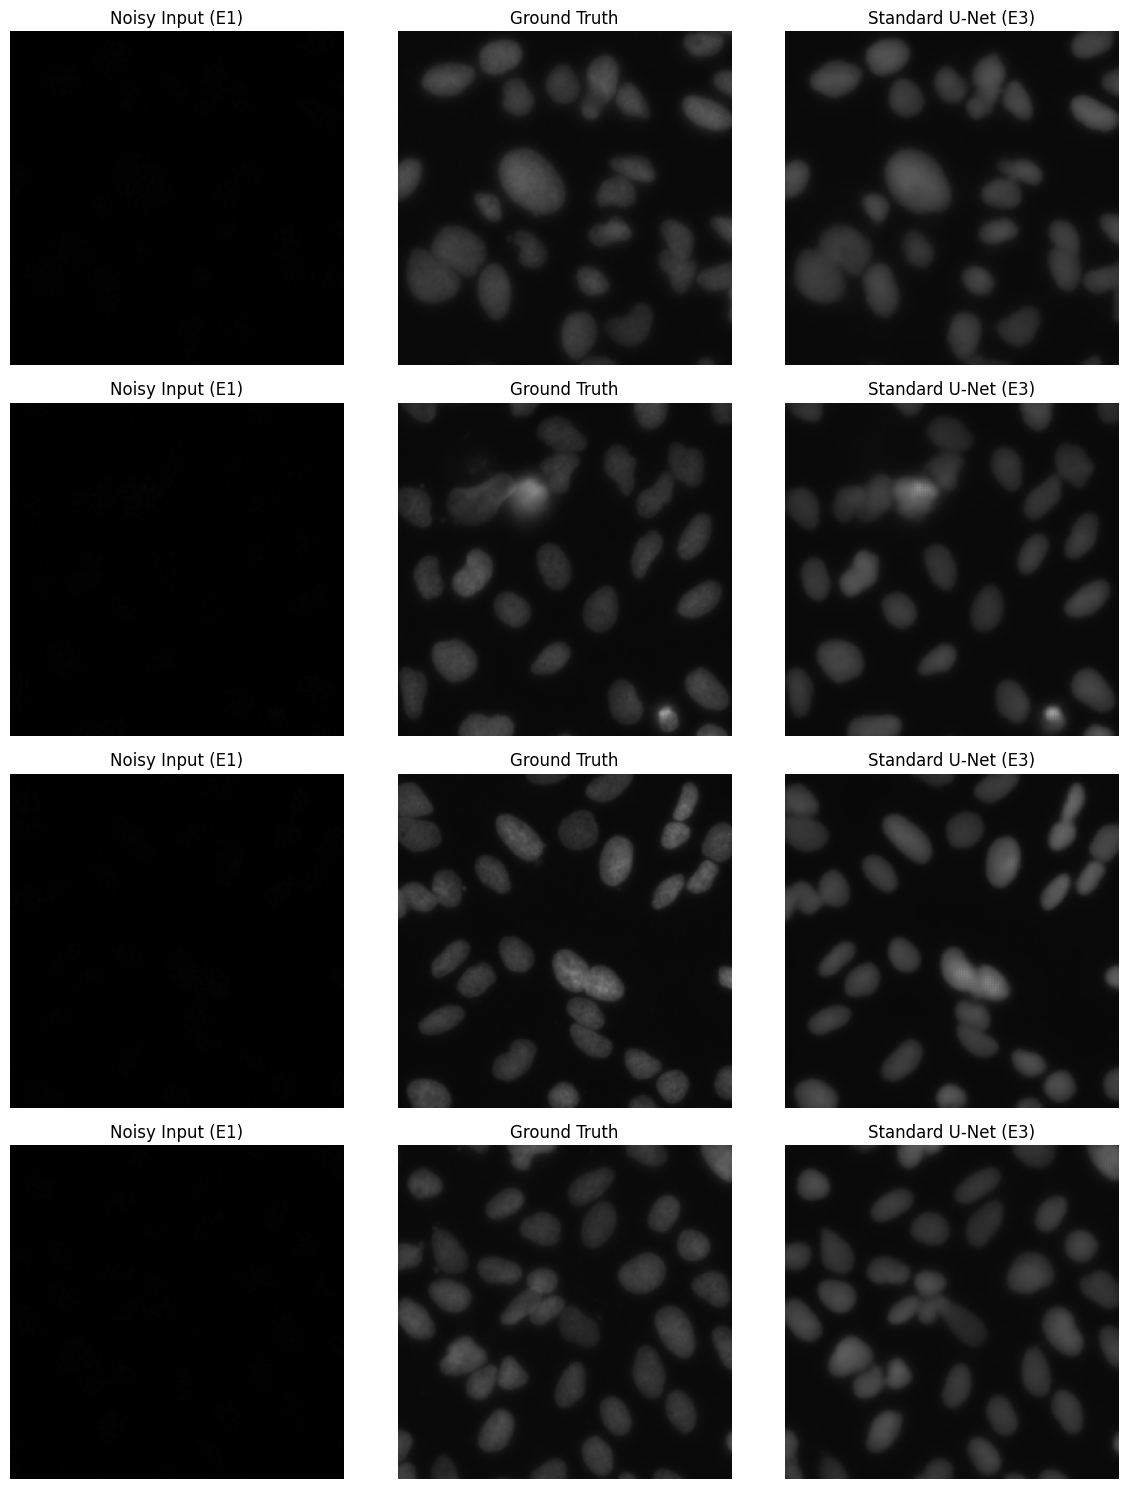

In [21]:
import torch
import numpy as np
import matplotlib.pyplot as plt

from skimage.metrics import peak_signal_noise_ratio, structural_similarity

# Load the best U-Net checkpoint
model.load_state_dict(
    torch.load("/content/best_unet.pth", map_location=device)
)

model.eval()

e1_psnr, e1_ssim = [], []
e3_psnr, e3_ssim = [], []

visual_samples = []

# Evaluate on untouched test images
with torch.no_grad():

    for noisy, gt in test_loader:

        noisy = noisy.to(device)
        gt = gt.to(device)

        prediction = model(noisy)

        for i in range(noisy.size(0)):

            x = noisy[i, 0].cpu().numpy()
            y = gt[i, 0].cpu().numpy()
            pred = prediction[i, 0].cpu().numpy()

            # Clamp predictions only for image-quality evaluation
            pred = np.clip(pred, 0, 1)
            x = np.clip(x, 0, 1)

            # E1: Original noisy input
            e1_psnr.append(peak_signal_noise_ratio(y, x, data_range=1))
            e1_ssim.append(structural_similarity(y, x, data_range=1))

            # E3: U-Net reconstruction
            e3_psnr.append(peak_signal_noise_ratio(y, pred, data_range=1))
            e3_ssim.append(structural_similarity(y, pred, data_range=1))

            if len(visual_samples) < 4:
                visual_samples.append((x, y, pred))


# Print evaluation results
print("TEST SET RESULTS")
print("=" * 50)

print(f"E1 Noisy Input | PSNR: {np.mean(e1_psnr):.3f} dB")
print(f"E1 Noisy Input | SSIM: {np.mean(e1_ssim):.4f}")

print("-" * 50)

print(f"E3 Standard U-Net | PSNR: {np.mean(e3_psnr):.3f} dB")
print(f"E3 Standard U-Net | SSIM: {np.mean(e3_ssim):.4f}")

print("-" * 50)

print(f"PSNR Improvement: {np.mean(e3_psnr) - np.mean(e1_psnr):.3f} dB")
print(f"SSIM Improvement: {np.mean(e3_ssim) - np.mean(e1_ssim):.4f}")


# Visual comparison
fig, axes = plt.subplots(4, 3, figsize=(12, 15))

for i, (noisy, gt, pred) in enumerate(visual_samples):

    for j, (image, title) in enumerate([
        (noisy, "Noisy Input (E1)"),
        (gt, "Ground Truth"),
        (pred, "Standard U-Net (E3)")
    ]):

        axes[i, j].imshow(image, cmap="gray", vmin=0, vmax=1)
        axes[i, j].set_title(title)
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

## Part 17 — E2: Traditional Denoising

Before relying on deep learning, we test two traditional image-denoising methods:

1. Gaussian Filtering – Smooths images to reduce random noise.
2. Median Filtering – Removes isolated noisy pixels while attempting to preserve edges.

Our dataset has a significant brightness difference between noisy inputs and ground truth. Therefore, we apply a fixed intensity correction calculated exclusively from the training pairs.

Both methods are evaluated against the same untouched test dataset used for E3.

We compare their PSNR, SSIM and visual reconstruction quality.

Training-derived intensity correction: 28.065

E2 TEST RESULTS

Gaussian Filtering
PSNR: 30.015 dB
SSIM: 0.6432

Median Filtering
PSNR: 27.431 dB
SSIM: 0.4593


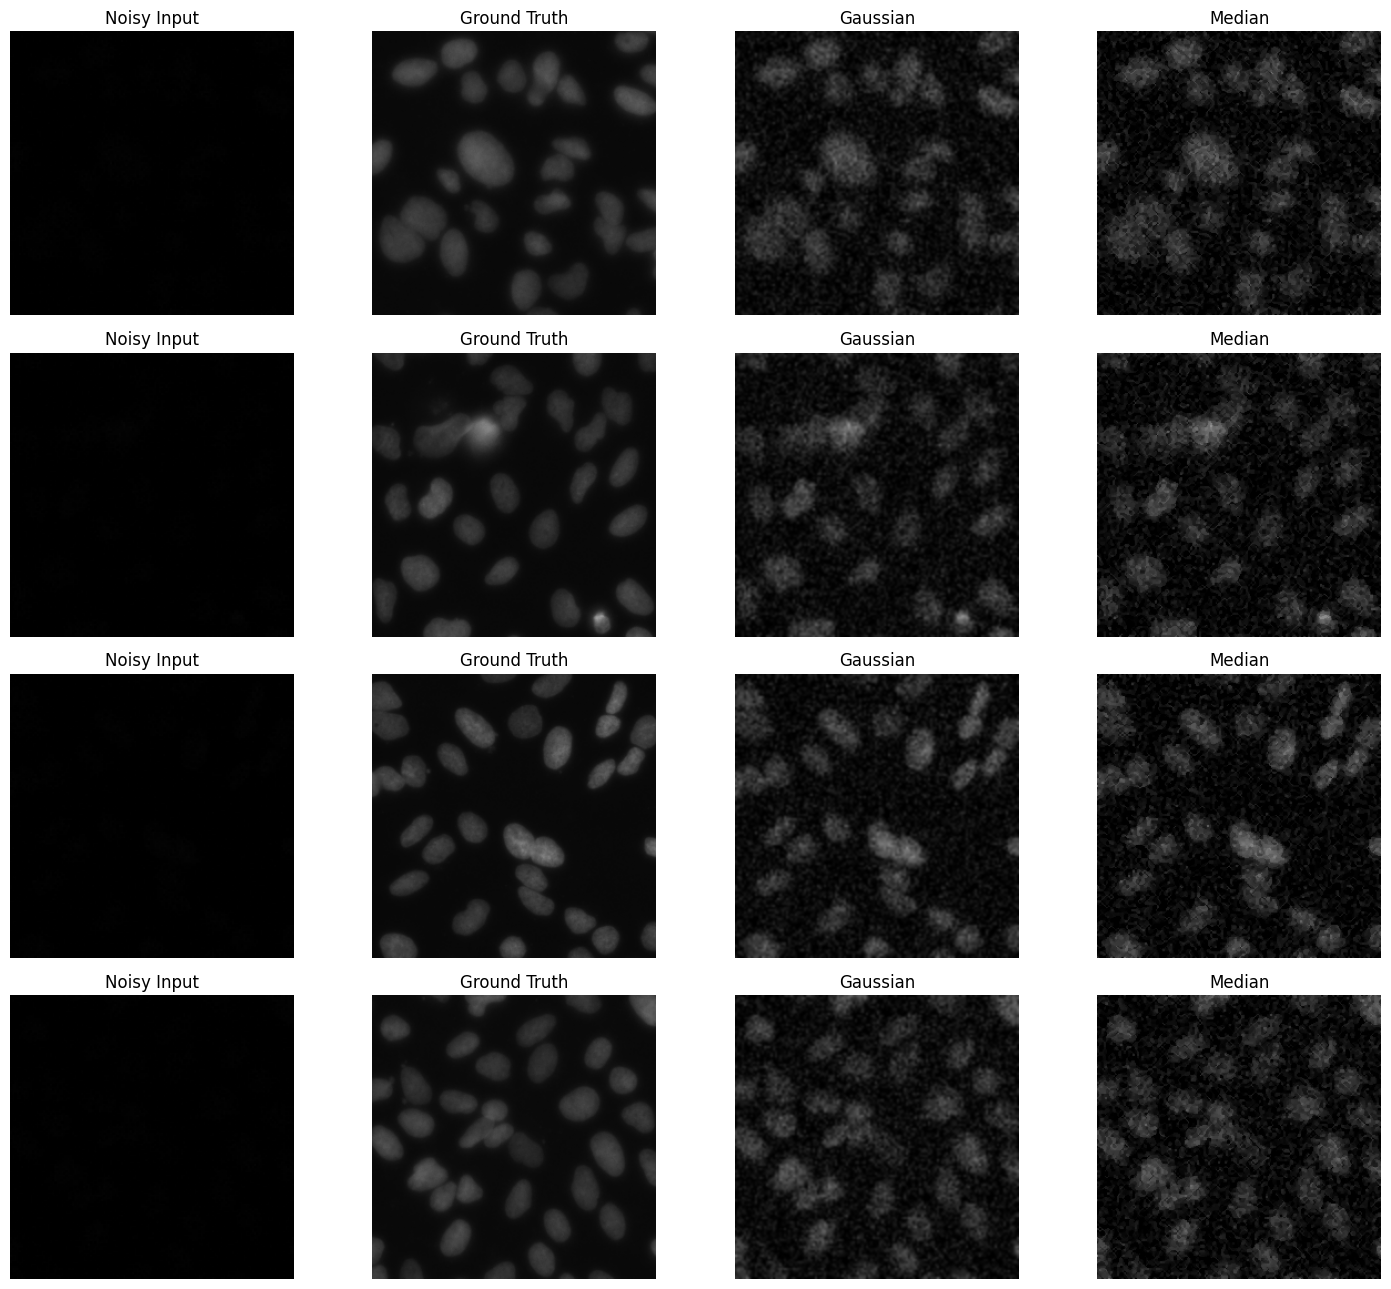

In [22]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.ndimage import gaussian_filter, median_filter
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

# 1. Calculate intensity correction using training pairs only
noisy_mean, gt_mean = 0, 0

for idx in train_idx:
    noisy_path, gt_path = small_pairs[idx]

    noisy = tifffile.imread(noisy_path).astype(np.float32)
    gt = tifffile.imread(gt_path).astype(np.float32)

    noisy_mean += noisy.mean()
    gt_mean += gt.mean()

intensity_gain = gt_mean / noisy_mean

print(f"Training-derived intensity correction: {intensity_gain:.3f}")


# 2. Evaluate traditional filters
results = {
    "Gaussian": {"psnr": [], "ssim": []},
    "Median": {"psnr": [], "ssim": []}
}

visual_samples = []

for noisy, gt in test_loader:

    for i in range(noisy.size(0)):

        x = noisy[i, 0].numpy()
        y = gt[i, 0].numpy()

        # Apply filtering followed by intensity correction
        gaussian = np.clip(
            gaussian_filter(x, sigma=1.0) * intensity_gain, 0, 1
        )

        median = np.clip(
            median_filter(x, size=3) * intensity_gain, 0, 1
        )

        # Calculate evaluation metrics
        for name, prediction in [
            ("Gaussian", gaussian),
            ("Median", median)
        ]:

            results[name]["psnr"].append(
                peak_signal_noise_ratio(y, prediction, data_range=1)
            )

            results[name]["ssim"].append(
                structural_similarity(y, prediction, data_range=1)
            )

        if len(visual_samples) < 4:
            visual_samples.append((x, y, gaussian, median))


# 3. Display results
print("\nE2 TEST RESULTS")
print("=" * 50)

for name, metrics in results.items():

    print(f"\n{name} Filtering")
    print(f"PSNR: {np.mean(metrics['psnr']):.3f} dB")
    print(f"SSIM: {np.mean(metrics['ssim']):.4f}")


# 4. Visual comparison
fig, axes = plt.subplots(4, 4, figsize=(15, 13))

titles = ["Noisy Input", "Ground Truth", "Gaussian", "Median"]

for i, sample in enumerate(visual_samples):

    for j, (image, title) in enumerate(zip(sample, titles)):

        axes[i, j].imshow(image, cmap="gray", vmin=0, vmax=1)
        axes[i, j].set_title(title)
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

## Part 18 — E4: U-Net with Edge Loss

Our standard U-Net achieves excellent reconstruction results, but some cellular details appear smoother than the ground truth.

We now investigate whether adding an edge-preservation objective can improve the reconstruction of cellular boundaries.

We introduce Sobel edge detection into the training loss.

The new loss combines:

1. L1 Loss – Measures pixel-level reconstruction differences.
2. Edge Loss – Measures differences between the predicted and actual image boundaries.

The architecture, dataset, training split and evaluation procedure remain unchanged.

Only the loss function is modified.

This experiment tests whether explicitly encouraging edge preservation improves microscopy image reconstruction.

In [23]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

# 1. Sobel filters for detecting image edges
class EdgeLoss(nn.Module):

    def __init__(self):
        super().__init__()

        sx = torch.tensor([
            [-1, 0, 1],
            [-2, 0, 2],
            [-1, 0, 1]
        ], dtype=torch.float32).view(1, 1, 3, 3)

        sy = sx.transpose(2, 3).contiguous()

        self.register_buffer("sx", sx)
        self.register_buffer("sy", sy)

    def forward(self, pred, target):

        px = F.conv2d(pred, self.sx, padding=1)
        py = F.conv2d(pred, self.sy, padding=1)

        tx = F.conv2d(target, self.sx, padding=1)
        ty = F.conv2d(target, self.sy, padding=1)

        return F.l1_loss(px, tx) + F.l1_loss(py, ty)


# 2. Initialize a fresh U-Net
model_e4 = UNet().to(device)

pixel_loss = nn.L1Loss()
edge_loss = EdgeLoss().to(device)

EDGE_WEIGHT = 0.1

optimizer = optim.Adam(model_e4.parameters(), lr=1e-4)

EPOCHS = 30
best_val_loss = float("inf")


# 3. Training
for epoch in range(EPOCHS):

    model_e4.train()
    train_loss = 0

    for noisy, gt in train_loader:

        noisy, gt = noisy.to(device), gt.to(device)

        optimizer.zero_grad()

        prediction = model_e4(noisy)

        loss = (
            pixel_loss(prediction, gt)
            + EDGE_WEIGHT * edge_loss(prediction, gt)
        )

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * noisy.size(0)

    train_loss /= len(train_ds)

    # 4. Validation
    model_e4.eval()
    val_pixel_loss = 0

    with torch.no_grad():

        for noisy, gt in val_loader:

            noisy, gt = noisy.to(device), gt.to(device)

            prediction = model_e4(noisy)

            loss = pixel_loss(prediction, gt)

            val_pixel_loss += loss.item() * noisy.size(0)

    val_pixel_loss /= len(val_ds)

    # Select checkpoint using validation pixel-level error
    if val_pixel_loss < best_val_loss:

        best_val_loss = val_pixel_loss

        torch.save(
            model_e4.state_dict(),
            "/content/best_unet_edge.pth"
        )

    print(
        f"Epoch [{epoch+1:02d}/{EPOCHS}] "
        f"Train Loss: {train_loss:.6f} "
        f"Val L1: {val_pixel_loss:.6f}"
    )


print("\nE4 Training Complete")
print("Best validation L1:", best_val_loss)
print("Model saved: /content/best_unet_edge.pth")

Epoch [01/30] Train Loss: 0.049100 Val L1: 0.008729
Epoch [02/30] Train Loss: 0.013939 Val L1: 0.008138
Epoch [03/30] Train Loss: 0.012635 Val L1: 0.006985
Epoch [04/30] Train Loss: 0.011860 Val L1: 0.006942
Epoch [05/30] Train Loss: 0.011517 Val L1: 0.006642
Epoch [06/30] Train Loss: 0.011149 Val L1: 0.006336
Epoch [07/30] Train Loss: 0.011040 Val L1: 0.007053
Epoch [08/30] Train Loss: 0.010817 Val L1: 0.008713
Epoch [09/30] Train Loss: 0.010696 Val L1: 0.006226
Epoch [10/30] Train Loss: 0.010578 Val L1: 0.009002
Epoch [11/30] Train Loss: 0.010380 Val L1: 0.005947
Epoch [12/30] Train Loss: 0.010259 Val L1: 0.006054
Epoch [13/30] Train Loss: 0.010263 Val L1: 0.006743
Epoch [14/30] Train Loss: 0.010077 Val L1: 0.005920
Epoch [15/30] Train Loss: 0.010179 Val L1: 0.006009
Epoch [16/30] Train Loss: 0.009878 Val L1: 0.006259
Epoch [17/30] Train Loss: 0.009993 Val L1: 0.005990
Epoch [18/30] Train Loss: 0.009755 Val L1: 0.006138
Epoch [19/30] Train Loss: 0.009728 Val L1: 0.006234
Epoch [20/30

## Part 19 — Comparing Standard U-Net and Edge-aware U-Net

We now compare our two trained models using the same untouched test dataset.

E3 uses standard L1 reconstruction loss.

E4 combines L1 reconstruction loss with Sobel edge loss.

We evaluate:

- PSNR: Overall reconstruction quality.
- SSIM: Structural similarity.
- Edge MAE: Difference between predicted and ground-truth image boundaries.

We also visualize their predictions side by side.

The objective is to determine whether edge-aware training improves cellular boundary preservation without sacrificing overall image quality.

E3 vs E4 — TEST RESULTS

E3
PSNR:    39.1700 dB
SSIM:    0.9705
Edge MAE: 0.003060

E4
PSNR:    39.3378 dB
SSIM:    0.9713
Edge MAE: 0.003096


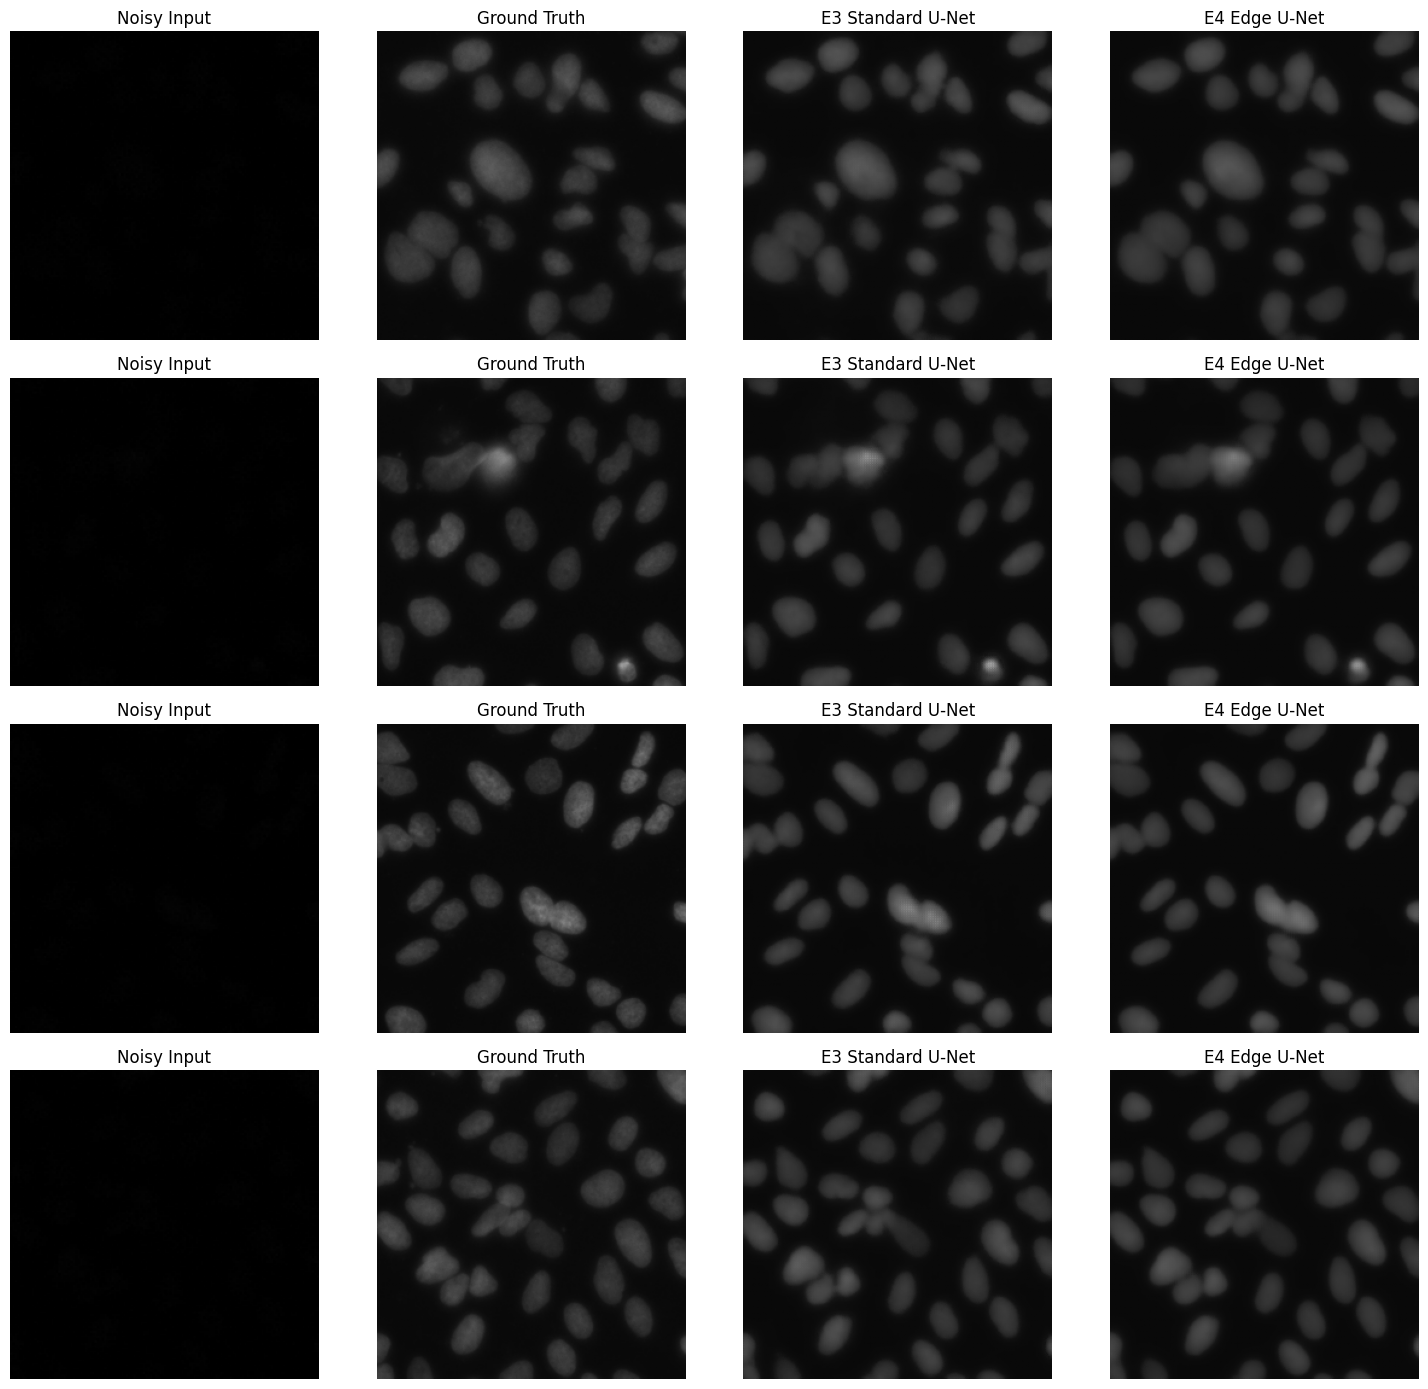

In [24]:
import torch
import numpy as np
import matplotlib.pyplot as plt

from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from skimage.filters import sobel

# 1. Load both best checkpoints
model_e3 = UNet().to(device)

model_e3.load_state_dict(
    torch.load("/content/best_unet.pth", map_location=device)
)

model_e4 = UNet().to(device)

model_e4.load_state_dict(
    torch.load("/content/best_unet_edge.pth", map_location=device)
)

model_e3.eval()
model_e4.eval()

# 2. Evaluation storage
results = {
    "E3": {"psnr": [], "ssim": [], "edge": []},
    "E4": {"psnr": [], "ssim": [], "edge": []}
}

visual_samples = []

# 3. Evaluate both models on identical test images
with torch.no_grad():

    for noisy, gt in test_loader:

        noisy, gt = noisy.to(device), gt.to(device)

        pred_e3 = model_e3(noisy)
        pred_e4 = model_e4(noisy)

        for i in range(noisy.size(0)):

            target = gt[i, 0].cpu().numpy()

            predictions = {
                "E3": pred_e3[i, 0].cpu().numpy(),
                "E4": pred_e4[i, 0].cpu().numpy()
            }

            for name, prediction in predictions.items():

                prediction = np.clip(prediction, 0, 1)

                results[name]["psnr"].append(
                    peak_signal_noise_ratio(
                        target, prediction, data_range=1
                    )
                )

                results[name]["ssim"].append(
                    structural_similarity(
                        target, prediction, data_range=1
                    )
                )

                # Compare predicted and actual edge maps
                edge_error = np.mean(
                    np.abs(sobel(prediction) - sobel(target))
                )

                results[name]["edge"].append(edge_error)

            if len(visual_samples) < 4:
                visual_samples.append((
                    noisy[i, 0].cpu().numpy(),
                    target,
                    np.clip(predictions["E3"], 0, 1),
                    np.clip(predictions["E4"], 0, 1)
                ))


# 4. Print comparative results
print("E3 vs E4 — TEST RESULTS")
print("=" * 55)

for name, metrics in results.items():

    print(f"\n{name}")

    print(f"PSNR:    {np.mean(metrics['psnr']):.4f} dB")
    print(f"SSIM:    {np.mean(metrics['ssim']):.4f}")
    print(f"Edge MAE: {np.mean(metrics['edge']):.6f}")


# 5. Visual comparison
fig, axes = plt.subplots(4, 4, figsize=(15, 14))

titles = ["Noisy Input", "Ground Truth", "E3 Standard U-Net", "E4 Edge U-Net"]

for i, sample in enumerate(visual_samples):

    for j, (image, title) in enumerate(zip(sample, titles)):

        axes[i, j].imshow(image, cmap="gray", vmin=0, vmax=1)
        axes[i, j].set_title(title)
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

## Part 20 — E5: Noise-aware U-Net

Our previous experiments used only the noisy image as input.

In this experiment, we provide the network with an additional piece of information: an estimate of the noise level in the image.

We estimate noise using differences between neighbouring pixels. This gives us an approximate noise level without requiring the ground-truth image.

The network now receives two input channels:

1. Original noisy image.
2. Estimated noise-level map.

The U-Net architecture otherwise remains unchanged.

We retain L1 loss, Adam optimizer, the same dataset splits and 30 training epochs.

Objective: Investigate whether explicitly providing noise information helps the network reconstruct cellular structures more accurately.

In [25]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np

# 1. Estimate noise level directly from the noisy image
def estimate_noise(x):

    dx = x[:, :, :, 1:] - x[:, :, :, :-1]
    dy = x[:, :, 1:, :] - x[:, :, :-1, :]

    differences = torch.cat(
        [dx.flatten(1), dy.flatten(1)], dim=1
    )

    median = differences.median(dim=1).values.unsqueeze(1)

    mad = (differences - median).abs().median(dim=1).values

    # Convert median absolute difference into an approximate noise standard deviation
    sigma = mad / (0.6745 * np.sqrt(2))

    return sigma.view(-1, 1, 1, 1)


# 2. Prepare the two-channel input
def prepare_noise_input(noisy):

    sigma = estimate_noise(noisy)

    noise_map = sigma.expand(
        -1, 1, noisy.shape[2], noisy.shape[3]
    )

    return torch.cat([noisy, noise_map], dim=1)


# 3. Same U-Net architecture, but with two input channels
class NoiseAwareUNet(nn.Module):

    def __init__(self):
        super().__init__()

        self.pool = nn.MaxPool2d(2)

        self.enc1 = ConvBlock(2, 32)
        self.enc2 = ConvBlock(32, 64)
        self.enc3 = ConvBlock(64, 128)
        self.enc4 = ConvBlock(128, 256)
        self.bottleneck = ConvBlock(256, 512)

        self.up4 = nn.ConvTranspose2d(512, 256, 2, 2)
        self.dec4 = ConvBlock(512, 256)

        self.up3 = nn.ConvTranspose2d(256, 128, 2, 2)
        self.dec3 = ConvBlock(256, 128)

        self.up2 = nn.ConvTranspose2d(128, 64, 2, 2)
        self.dec2 = ConvBlock(128, 64)

        self.up1 = nn.ConvTranspose2d(64, 32, 2, 2)
        self.dec1 = ConvBlock(64, 32)

        self.final = nn.Conv2d(32, 1, 1)

    def forward(self, x):

        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = self.dec4(torch.cat([self.up4(b), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))

        return self.final(d1)


# 4. Initialize model and training settings
model_e5 = NoiseAwareUNet().to(device)

criterion = nn.L1Loss()
optimizer = optim.Adam(model_e5.parameters(), lr=1e-4)

EPOCHS = 30
best_val_loss = float("inf")

print("Device:", device)
print("Model parameters:", sum(p.numel() for p in model_e5.parameters()))


# 5. Training
for epoch in range(EPOCHS):

    model_e5.train()
    train_loss = 0

    for noisy, gt in train_loader:

        noisy, gt = noisy.to(device), gt.to(device)

        inputs = prepare_noise_input(noisy)

        optimizer.zero_grad()

        prediction = model_e5(inputs)
        loss = criterion(prediction, gt)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * noisy.size(0)

    train_loss /= len(train_ds)

    # 6. Validation
    model_e5.eval()
    val_loss = 0

    with torch.no_grad():

        for noisy, gt in val_loader:

            noisy, gt = noisy.to(device), gt.to(device)

            inputs = prepare_noise_input(noisy)
            prediction = model_e5(inputs)

            loss = criterion(prediction, gt)

            val_loss += loss.item() * noisy.size(0)

    val_loss /= len(val_ds)

    # 7. Save best model
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save(
            model_e5.state_dict(),
            "/content/best_unet_noise.pth"
        )

    print(
        f"Epoch [{epoch+1:02d}/{EPOCHS}] "
        f"Train Loss: {train_loss:.6f} "
        f"Val Loss: {val_loss:.6f}"
    )


print("\nE5 Training Complete")
print("Best validation loss:", best_val_loss)
print("Model saved: /content/best_unet_noise.pth")

Device: cuda
Model parameters: 7765697
Epoch [01/30] Train Loss: 0.055019 Val Loss: 0.017095
Epoch [02/30] Train Loss: 0.014540 Val Loss: 0.009757
Epoch [03/30] Train Loss: 0.012279 Val Loss: 0.009741
Epoch [04/30] Train Loss: 0.011022 Val Loss: 0.009398
Epoch [05/30] Train Loss: 0.010327 Val Loss: 0.009099
Epoch [06/30] Train Loss: 0.009513 Val Loss: 0.008119
Epoch [07/30] Train Loss: 0.009407 Val Loss: 0.007288
Epoch [08/30] Train Loss: 0.008968 Val Loss: 0.007655
Epoch [09/30] Train Loss: 0.008882 Val Loss: 0.010696
Epoch [10/30] Train Loss: 0.008704 Val Loss: 0.007529
Epoch [11/30] Train Loss: 0.008405 Val Loss: 0.007343
Epoch [12/30] Train Loss: 0.008312 Val Loss: 0.007007
Epoch [13/30] Train Loss: 0.008045 Val Loss: 0.007763
Epoch [14/30] Train Loss: 0.007998 Val Loss: 0.006702
Epoch [15/30] Train Loss: 0.007912 Val Loss: 0.007516
Epoch [16/30] Train Loss: 0.008499 Val Loss: 0.007633
Epoch [17/30] Train Loss: 0.008054 Val Loss: 0.006874
Epoch [18/30] Train Loss: 0.007812 Val Loss

## E5 – Noise-Aware U-Net: Test Evaluation

We now evaluate the noise-aware U-Net against our previous models.

All models use the same test images and are evaluated using:

- **PSNR:** How close the reconstructed image is to the ground truth.
- **SSIM:** How similar the reconstructed image structure is.
- **Edge MAE:** How accurately the model preserves image boundaries.

This experiment determines whether providing additional noise information
helps the model reconstruct microscopy images more accurately.

E3 vs E4 vs E5 — TEST RESULTS


,PSNR (dB),SSIM,Edge MAE
E3 Standard U-Net,39.16997,0.97053,0.00306
E4 Edge U-Net,39.33782,0.97135,0.00310
E5 Noise-Aware U-Net,38.79151,0.96835,0.00320


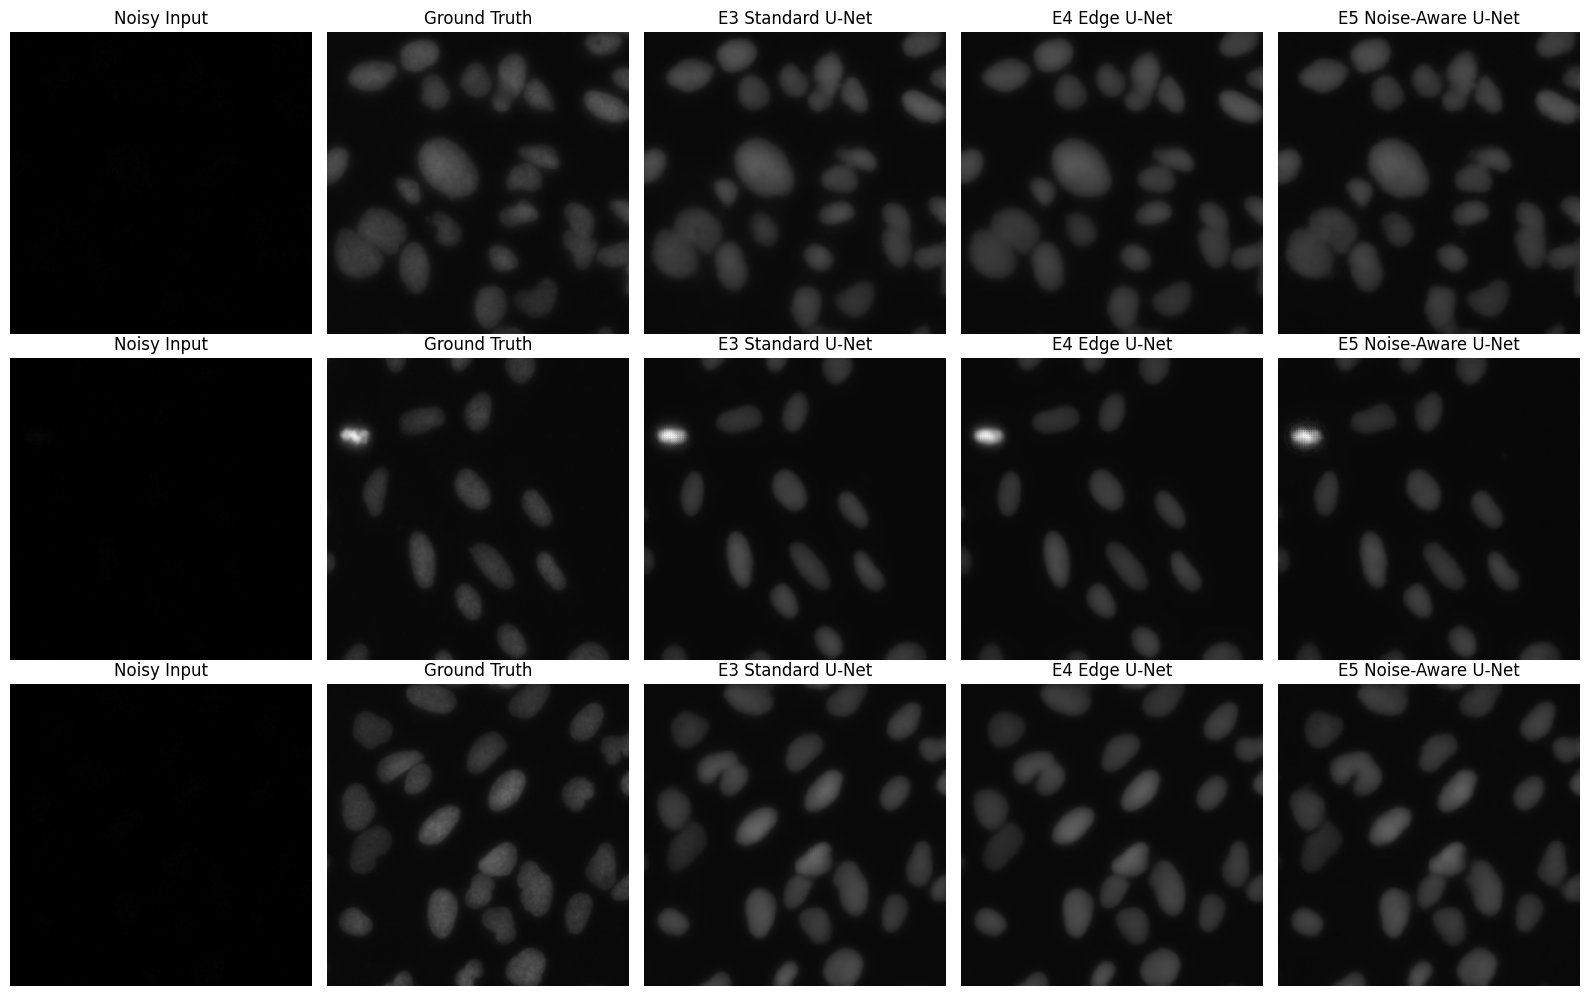

In [26]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from skimage.filters import sobel

# Load all three models
model_e3 = UNet().to(device)
model_e4 = UNet().to(device)
model_e5 = NoiseAwareUNet().to(device)

model_e3.load_state_dict(torch.load('/content/best_unet.pth', map_location=device))
model_e4.load_state_dict(torch.load('/content/best_unet_edge.pth', map_location=device))
model_e5.load_state_dict(torch.load('/content/best_unet_noise.pth', map_location=device))

models = {
    "E3 Standard U-Net": model_e3,
    "E4 Edge U-Net": model_e4,
    "E5 Noise-Aware U-Net": model_e5
}

for model in models.values():
    model.eval()

results = {name: [] for name in models}
examples = []

# Evaluate using identical test images
with torch.no_grad():
    for noisy, gt in test_loader:
        noisy, gt = noisy.to(device), gt.to(device)

        predictions = {
            "E3 Standard U-Net": model_e3(noisy),
            "E4 Edge U-Net": model_e4(noisy),
            "E5 Noise-Aware U-Net": model_e5(prepare_noise_input(noisy))
        }

        for name, prediction in predictions.items():
            prediction = prediction.clamp(0, 1)

            for p, target in zip(prediction.cpu().numpy(),
                                 gt.cpu().numpy()):

                p, target = p.squeeze(), target.squeeze()

                results[name].append([
                    peak_signal_noise_ratio(target, p, data_range=1.0),
                    structural_similarity(target, p, data_range=1.0),
                    np.mean(np.abs(sobel(p) - sobel(target)))
                ])

        # Keep a few examples for visual comparison
        if len(examples) < 3:
            examples.append((
                noisy[0].cpu().squeeze().numpy(),
                gt[0].cpu().squeeze().numpy(),
                {k: v[0].cpu().squeeze().numpy()
                 for k, v in predictions.items()}
            ))

# Display average test metrics
summary = pd.DataFrame({
    name: np.mean(values, axis=0)
    for name, values in results.items()
}, index=["PSNR (dB)", "SSIM", "Edge MAE"]).T

print("E3 vs E4 vs E5 — TEST RESULTS")
display(summary.round(5))

# Visual comparison
fig, axes = plt.subplots(3, 5, figsize=(16, 10))

for i, (noisy, gt, predictions) in enumerate(examples):
    images = [
        noisy, gt,
        predictions["E3 Standard U-Net"],
        predictions["E4 Edge U-Net"],
        predictions["E5 Noise-Aware U-Net"]
    ]

    titles = ["Noisy Input", "Ground Truth",
              "E3 Standard U-Net", "E4 Edge U-Net",
              "E5 Noise-Aware U-Net"]

    for j, (img, title) in enumerate(zip(images, titles)):
        axes[i, j].imshow(img, cmap="gray", vmin=0, vmax=1)
        axes[i, j].set_title(title)
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

## Nuclei Detail Preservation – E3, E4 and E5

Although our models achieve high PSNR and SSIM scores, their
predictions appear smoother than the ground truth.

This experiment investigates whether important nuclei details
are being lost during denoising.

We will:
- Zoom into individual nuclei for visual comparison.
- Compare reconstruction quality specifically inside nuclei.
- Examine intensity variations within nuclei.
- Compare how well each model preserves image boundaries.

The purpose is to determine whether our models remove noise
while retaining the biological details of the original images.

NUCLEI DETAIL PRESERVATION RESULTS


,Foreground PSNR (dB),Foreground Edge MAE
E3,33.137451,0.00847
E4,33.372250,0.00848
E5,32.830120,0.00884


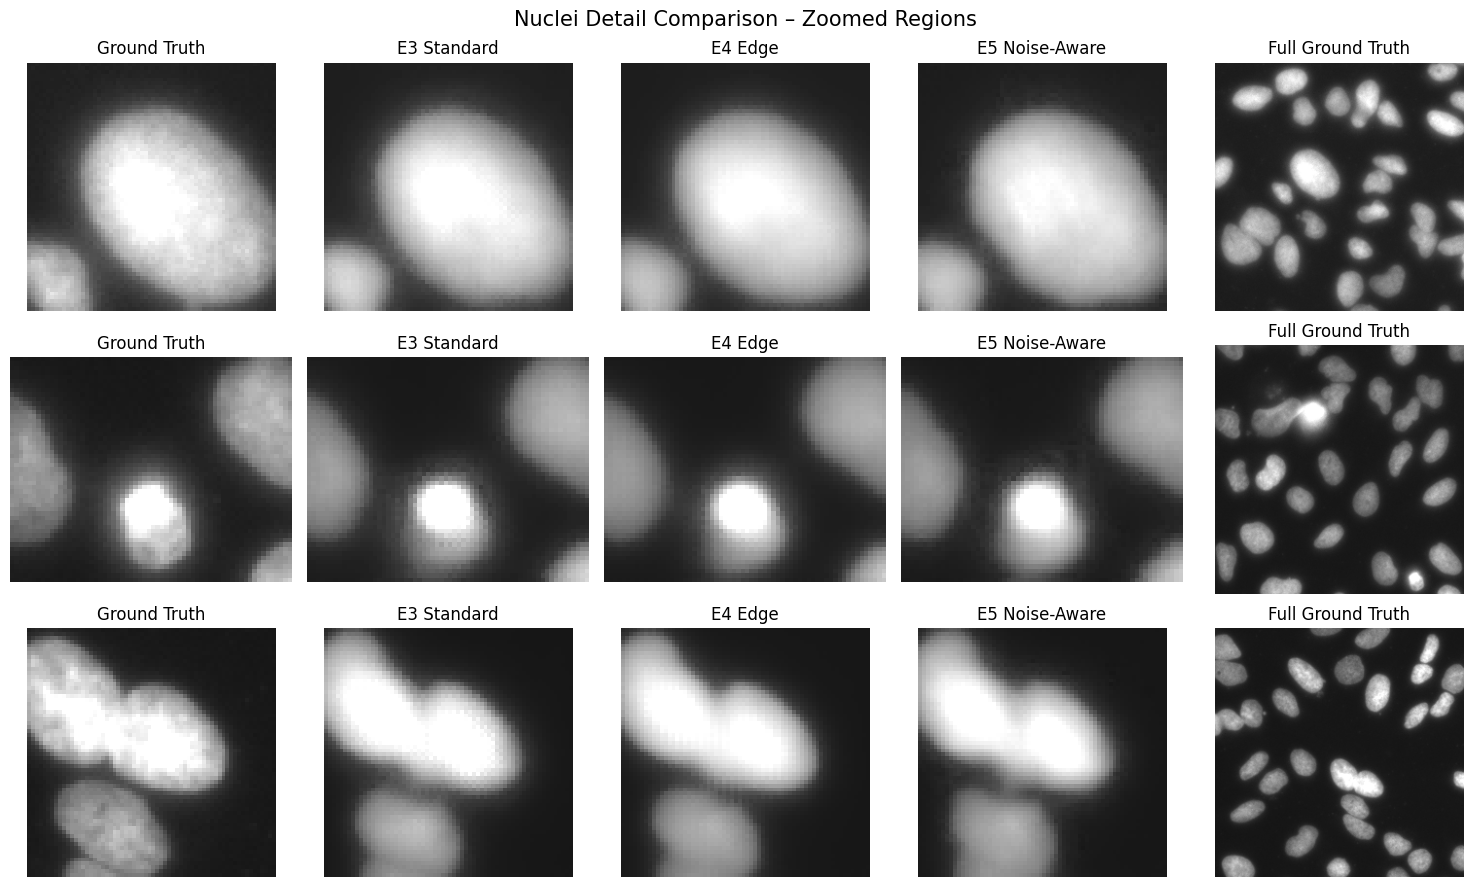

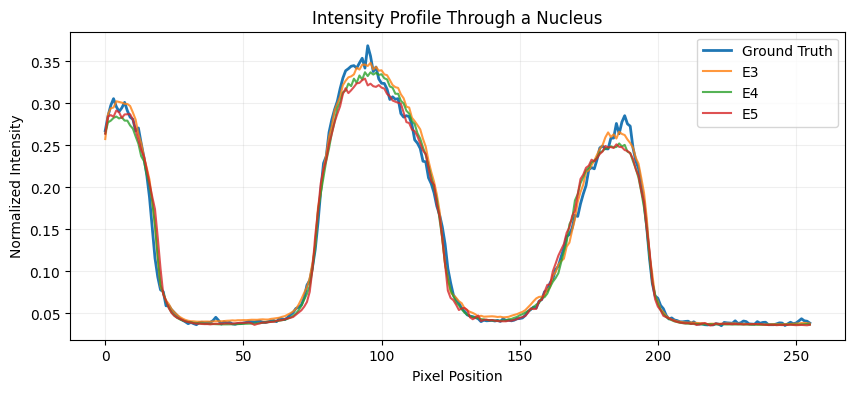

In [27]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import pandas as pd

from skimage.filters import threshold_otsu, sobel

# Models already trained and loaded in previous experiments
models = {
    "E3": model_e3,
    "E4": model_e4,
    "E5": model_e5
}

for model in models.values():
    model.eval()

results = {name: [] for name in models}
examples = []

# Evaluate the complete test set
with torch.no_grad():
    for noisy, gt in test_loader:

        noisy, gt = noisy.to(device), gt.to(device)

        predictions = {
            "E3": model_e3(noisy),
            "E4": model_e4(noisy),
            "E5": model_e5(prepare_noise_input(noisy))
        }

        for i in range(len(gt)):

            target = gt[i, 0].cpu().numpy()

            # Identify nuclei pixels using the ground truth
            mask = target > threshold_otsu(target)

            # Ignore images without meaningful foreground
            if mask.sum() < 20:
                continue

            row = {}

            for name, prediction in predictions.items():

                pred = prediction[i, 0].clamp(0, 1).cpu().numpy()

                # Reconstruction quality inside nuclei
                mse = np.mean((target[mask] - pred[mask]) ** 2)
                psnr = 10 * np.log10(1.0 / max(mse, 1e-12))

                # Boundary preservation inside nuclei
                edge_mae = np.mean(
                    np.abs(sobel(target)[mask] - sobel(pred)[mask])
                )

                row[name] = [psnr, edge_mae]

            for name in models:
                results[name].append(row[name])

            # Keep three examples for visual inspection
            if len(examples) < 3:
                examples.append({
                    "gt": target,
                    "predictions": {
                        name: predictions[name][i, 0].clamp(0, 1)
                        .cpu().numpy()
                        for name in models
                    }
                })

# Display foreground-specific results
summary = pd.DataFrame({
    name: np.mean(values, axis=0)
    for name, values in results.items()
}, index=["Foreground PSNR (dB)", "Foreground Edge MAE"]).T

print("NUCLEI DETAIL PRESERVATION RESULTS")
display(summary.round(5))


# Zoom into nuclei and compare all models
fig, axes = plt.subplots(3, 5, figsize=(15, 9))

for i, example in enumerate(examples):

    gt = example["gt"]

    # Centre the crop around the brightest nucleus region
    y, x = np.unravel_index(np.argmax(gt), gt.shape)

    size = 64
    y1, y2 = max(0, y-size//2), min(256, y+size//2)
    x1, x2 = max(0, x-size//2), min(256, x+size//2)

    images = [
        gt,
        example["predictions"]["E3"],
        example["predictions"]["E4"],
        example["predictions"]["E5"]
    ]

    titles = ["Ground Truth", "E3 Standard", "E4 Edge", "E5 Noise-Aware"]

    # Shared intensity range for fair visual comparison
    vmax = max(np.percentile(gt, 99.5), 0.01)

    axes[i, 0].imshow(
        gt[y1:y2, x1:x2], cmap="gray", vmin=0, vmax=vmax
    )
    axes[i, 0].set_title("Ground Truth")

    for j, (img, title) in enumerate(zip(images[1:], titles[1:]), 1):
        axes[i, j].imshow(
            img[y1:y2, x1:x2], cmap="gray", vmin=0, vmax=vmax
        )
        axes[i, j].set_title(title)

    # Show the original full image for context
    axes[i, 4].imshow(gt, cmap="gray", vmin=0, vmax=vmax)
    axes[i, 4].set_title("Full Ground Truth")

    for ax in axes[i]:
        ax.axis("off")

plt.suptitle("Nuclei Detail Comparison – Zoomed Regions", fontsize=15)
plt.tight_layout()
plt.show()


# Compare intensity profiles through the brightest nucleus
example = examples[0]
gt = example["gt"]

y, x = np.unravel_index(np.argmax(gt), gt.shape)

plt.figure(figsize=(10, 4))

plt.plot(gt[y, :], label="Ground Truth", linewidth=2)

for name, prediction in example["predictions"].items():
    plt.plot(prediction[y, :], label=name, alpha=0.8)

plt.title("Intensity Profile Through a Nucleus")
plt.xlabel("Pixel Position")
plt.ylabel("Normalized Intensity")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## E6 — Combined Noise-Aware and Edge-Aware U-Net

### Objective
Previous experiments (E3, E4 and E5) showed that neither edge awareness nor noise awareness independently improved nucleus detail preservation. E6 combines both approaches to investigate whether they can work together.

### Approach
- **Noise awareness:** Provides additional information about the noise present in the input image.
- **Edge awareness:** Uses Sobel filters to encourage preservation of nucleus boundaries.
- **Combined loss:** Combines pixel-level L1 loss with edge loss.

**Loss Function:**

\[
L = L1 + 0.1 * (edge)
\]

### Training Configuration
- Architecture: NoiseAwareUNet
- Optimizer: Adam
- Learning Rate: 0.0001
- Epochs: 30
- Loss: L1 + Weighted Edge Loss
- Model Selection: Lowest validation L1
- Dataset: Same training and validation splits used in previous experiments.

### Evaluation
E6 will be compared against E3, E4 and E5 using:

1. PSNR
2. SSIM
3. Foreground PSNR
4. Foreground Edge MAE
5. Visual comparison of nucleus boundaries and internal structures.

**Expected Outcome:** Determine whether combining noise and edge awareness improves structural detail preservation without sacrificing overall denoising performance.

In [28]:
import torch
import torch.nn.functional as F
import torch.optim as optim

# E6: Combine noise awareness with edge preservation
model_e6 = NoiseAwareUNet().to(device)

# Sobel filters for detecting image edges
sobel_x = torch.tensor(
    [[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]],
    dtype=torch.float32, device=device
).view(1, 1, 3, 3) / 8

sobel_y = sobel_x.transpose(2, 3)

def edge_loss(pred, target):
    px = F.conv2d(pred, sobel_x, padding=1)
    py = F.conv2d(pred, sobel_y, padding=1)
    tx = F.conv2d(target, sobel_x, padding=1)
    ty = F.conv2d(target, sobel_y, padding=1)

    return F.l1_loss(px, tx) + F.l1_loss(py, ty)


EDGE_WEIGHT = 0.1
optimizer_e6 = optim.Adam(model_e6.parameters(), lr=1e-4)

best_val_loss = float("inf")
EPOCHS = 30

for epoch in range(EPOCHS):

    # Training
    model_e6.train()
    train_loss = 0

    for noisy, target in train_loader:
        noisy, target = noisy.to(device), target.to(device)

        optimizer_e6.zero_grad()

        pred = model_e6(prepare_noise_input(noisy))

        loss = (
            F.l1_loss(pred, target)
            + EDGE_WEIGHT * edge_loss(pred, target)
        )

        loss.backward()
        optimizer_e6.step()

        train_loss += loss.item()

    # Validation: use pixel L1 for consistent model selection
    model_e6.eval()
    val_loss = 0

    with torch.no_grad():
        for noisy, target in val_loader:
            noisy, target = noisy.to(device), target.to(device)

            pred = model_e6(prepare_noise_input(noisy))
            val_loss += F.l1_loss(pred, target).item()

    train_loss /= len(train_loader)
    val_loss /= len(val_loader)

    print(
        f"Epoch [{epoch+1:02d}/{EPOCHS}] "
        f"Train Loss: {train_loss:.6f} "
        f"Val L1: {val_loss:.6f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model_e6.state_dict(), "/content/best_unet_combined.pth")

print("\nE6 Training Complete")
print("Best validation L1:", best_val_loss)
print("Model saved: /content/best_unet_combined.pth")

Epoch [01/30] Train Loss: 0.058383 Val L1: 0.014602
Epoch [02/30] Train Loss: 0.015816 Val L1: 0.013311
Epoch [03/30] Train Loss: 0.013923 Val L1: 0.010586
Epoch [04/30] Train Loss: 0.012194 Val L1: 0.008618
Epoch [05/30] Train Loss: 0.010680 Val L1: 0.008741
Epoch [06/30] Train Loss: 0.011079 Val L1: 0.007809
Epoch [07/30] Train Loss: 0.009983 Val L1: 0.007836
Epoch [08/30] Train Loss: 0.009882 Val L1: 0.007601
Epoch [09/30] Train Loss: 0.009380 Val L1: 0.007280
Epoch [10/30] Train Loss: 0.008960 Val L1: 0.007007
Epoch [11/30] Train Loss: 0.008984 Val L1: 0.007008
Epoch [12/30] Train Loss: 0.008613 Val L1: 0.006949
Epoch [13/30] Train Loss: 0.008364 Val L1: 0.007543
Epoch [14/30] Train Loss: 0.008200 Val L1: 0.006977
Epoch [15/30] Train Loss: 0.008329 Val L1: 0.006770
Epoch [16/30] Train Loss: 0.007930 Val L1: 0.006690
Epoch [17/30] Train Loss: 0.007992 Val L1: 0.006547
Epoch [18/30] Train Loss: 0.007826 Val L1: 0.006698
Epoch [19/30] Train Loss: 0.007639 Val L1: 0.006442
Epoch [20/30

## E6 — Combined Noise-Aware and Edge-Aware U-Net: Test Evaluation

### Training Results
E6 combines noise awareness and edge preservation using a weighted L1 and Sobel edge loss.

- Architecture: NoiseAwareUNet
- Optimizer: Adam
- Learning Rate: 0.0001
- Epochs: 30
- Edge Loss Weight: 0.1
- Best Validation L1: 0.006130881382212523

### Observation

E6 achieved stable convergence but did not outperform the previous experiments in validation loss.

The combined approach did not demonstrate a clear advantage over the Standard U-Net (E3).

### Next Step

Evaluate E6 on the unchanged test set and compare PSNR, SSIM, Foreground PSNR and Foreground Edge MAE against E3, E4 and E5.

The primary objective remains preserving actual nucleus structures and internal details rather than optimizing image similarity metrics alone.

In [29]:
import torch
import torch.nn.functional as F
import numpy as np
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

# Load the best E6 checkpoint
model_e6.load_state_dict(
    torch.load("/content/best_unet_combined.pth", map_location=device)
)
model_e6.eval()

e6_results = {"PSNR": [], "SSIM": [], "Foreground PSNR": [], "Edge MAE": []}

with torch.no_grad():
    for noisy, target in test_loader:
        noisy, target = noisy.to(device), target.to(device)

        pred = model_e6(prepare_noise_input(noisy))

        for p, gt in zip(pred.cpu().numpy(), target.cpu().numpy()):
            p, gt = p.squeeze(), gt.squeeze()


            # U-Net predictions are already in the target intensity scale
            p = np.clip(p, 0, 1)
            gt = np.clip(gt, 0, 1)

            e6_results["PSNR"].append(
                peak_signal_noise_ratio(gt, p, data_range=1.0)
            )
            e6_results["SSIM"].append(
                structural_similarity(gt, p, data_range=1.0)
            )

            # Evaluate foreground pixels separately
            mask = gt > 0.05

            if mask.any():
                e6_results["Foreground PSNR"].append(
                    peak_signal_noise_ratio(
                        gt[mask], p[mask], data_range=1.0
                    )
                )

            # Compare Sobel edge maps
            gx = F.conv2d(
                torch.tensor(p).float()[None, None].to(device),
                sobel_x, padding=1
            )
            gy = F.conv2d(
                torch.tensor(p).float()[None, None].to(device),
                sobel_y, padding=1
            )

            tx = F.conv2d(
                torch.tensor(gt).float()[None, None].to(device),
                sobel_x, padding=1
            )
            ty = F.conv2d(
                torch.tensor(gt).float()[None, None].to(device),
                sobel_y, padding=1
            )

            edge_mae = (
                torch.abs(gx - tx) + torch.abs(gy - ty)
            ).mean().item()

            e6_results["Edge MAE"].append(edge_mae)

# Display results
print("=" * 45)
print("E6 COMBINED U-NET — TEST RESULTS")
print("=" * 45)

for metric, values in e6_results.items():
    print(f"{metric}: {np.mean(values):.5f}")

print("=" * 45)

E6 COMBINED U-NET — TEST RESULTS
PSNR: 38.88985
SSIM: 0.96897
Foreground PSNR: 33.34676
Edge MAE: 0.00388


**Research experiment status**
| Experiment | Description | Current conclusion |
|---|---|---|
| E1 | Noisy Input | Starting point |
| E2 | Gaussian / Median | Classical baseline |
| E3 | Standard U-Net | Best overall |
| E4 | U-Net + Edge Loss | No demonstrated improvement |
| E5 | Noise-Aware U-Net | No demonstrated improvement |
| E6 | Noise-Aware + Edge Loss | Slight foreground PSNR improvement, worse overall metrics |

- ***Compare the same test image across E3, E4, E5 and E6, side by side
with the noisy input and ground truth.***

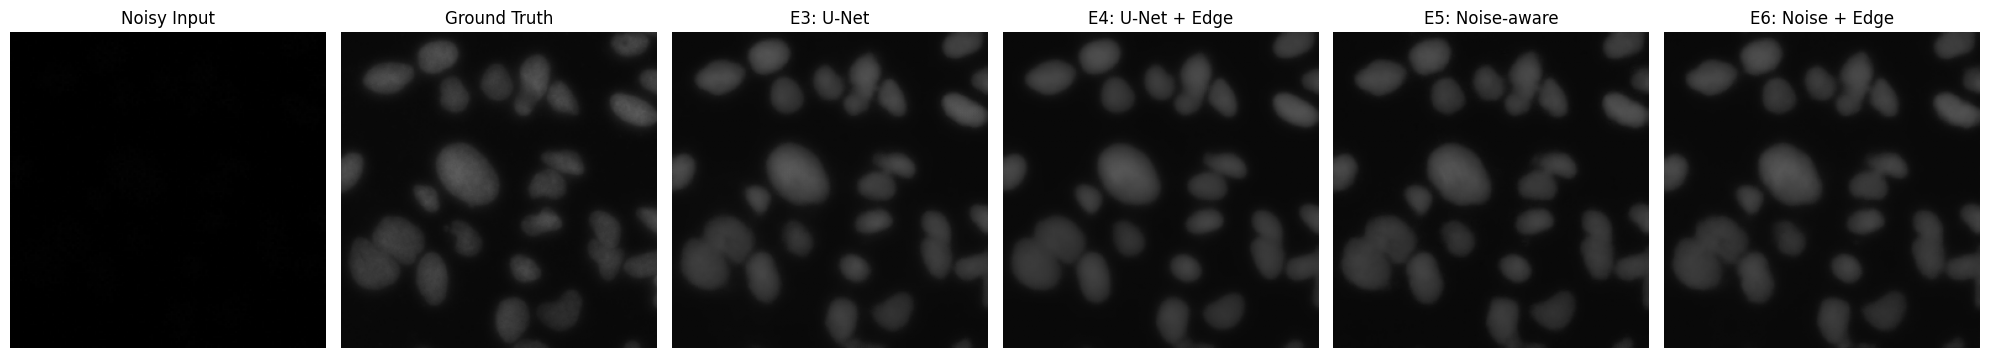

In [30]:
# Visual comparison: E3, E4, E5, E6
import matplotlib.pyplot as plt
import torch

models = {
    "E3: U-Net": (UNet(), "/content/best_unet.pth", False),
    "E4: U-Net + Edge": (UNet(), "/content/best_unet_edge.pth", False),
    "E5: Noise-aware": (NoiseAwareUNet(), "/content/best_unet_noise.pth", True),
    "E6: Noise + Edge": (NoiseAwareUNet(), "/content/best_unet_combined.pth", True),
}

# Get one test image
noisy, target = next(iter(test_loader))
noisy, target = noisy[:1].to(device), target[:1].to(device)

predictions = {}

for name, (model, path, noise_aware) in models.items():
    model.load_state_dict(torch.load(path, map_location=device))
    model = model.to(device).eval()

    with torch.no_grad():
        model_input = prepare_noise_input(noisy) if noise_aware else noisy
        pred = model(model_input).clamp(0, 1)

    predictions[name] = pred[0, 0].cpu().numpy()

# Display images
images = [
    ("Noisy Input", noisy[0, 0].cpu().numpy()),
    ("Ground Truth", target[0, 0].cpu().numpy()),
    *predictions.items()
]

fig, axes = plt.subplots(1, len(images), figsize=(20, 4))

for ax, (title, img) in zip(axes, images):
    ax.imshow(img, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

- ***Zoomed In central region of all images***

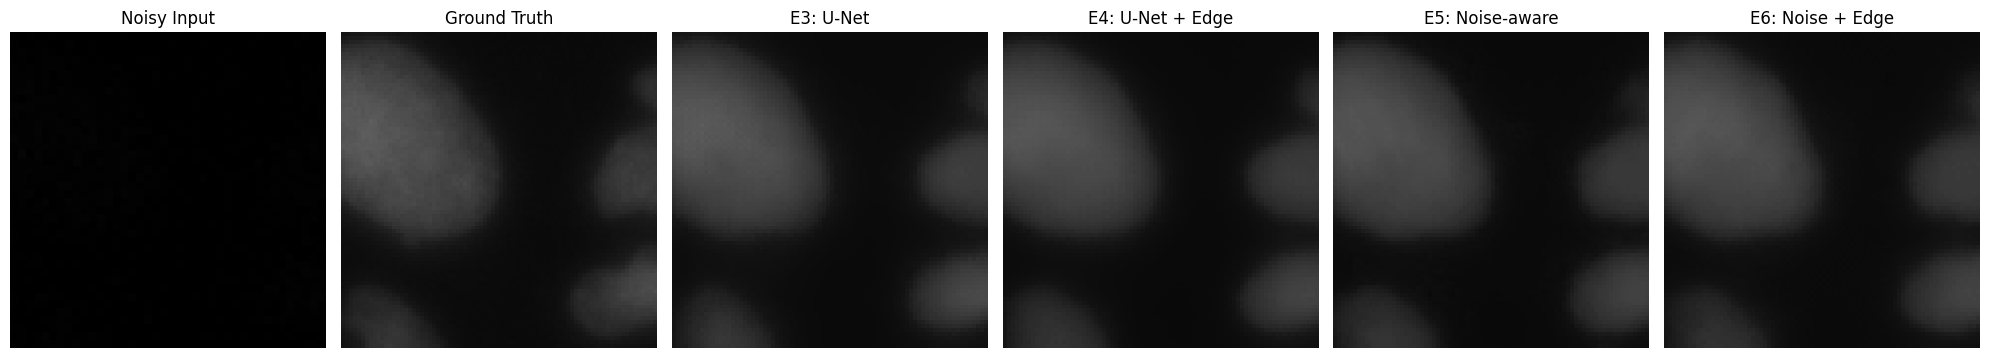

In [31]:
# Zoom into the central region of all images
h, w = target.shape[-2:]
y1, y2 = h // 2 - 40, h // 2 + 40
x1, x2 = w // 2 - 40, w // 2 + 40

fig, axes = plt.subplots(1, len(images), figsize=(20, 4))

for ax, (title, img) in zip(axes, images):
    ax.imshow(img[y1:y2, x1:x2], cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

## E7: Attention U-Net

In this experiment, we introduce attention gates into the standard U-Net architecture.

The attention gates help the model focus on relevant image regions while using skip connections.

**Goal:** Improve denoising while preserving fine biological structures such as nuclei.

- Same dataset and split as E3
- Input: Noisy image
- Loss: L1
- Optimizer: Adam
- Epochs: 30

We compare E7 against E3 using PSNR, SSIM, foreground PSNR, and visual inspection.

In [33]:
# E7: Attention U-Net
import torch
import torch.nn as nn
import torch.nn.functional as F

class AttentionGate(nn.Module):
    def __init__(self, skip_channels, gate_channels, inter_channels):
        super().__init__()

        self.skip_conv = nn.Conv2d(skip_channels, inter_channels, 1)
        self.gate_conv = nn.Conv2d(gate_channels, inter_channels, 1)
        self.attention = nn.Sequential(
            nn.ReLU(inplace=True),
            nn.Conv2d(inter_channels, 1, 1),
            nn.Sigmoid()
        )

    def forward(self, skip, gate):
        attention = self.attention(
            self.skip_conv(skip) + self.gate_conv(gate)
        )
        return skip * attention


class AttentionUNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.pool = nn.MaxPool2d(2)

        self.enc1 = ConvBlock(1, 32)
        self.enc2 = ConvBlock(32, 64)
        self.enc3 = ConvBlock(64, 128)
        self.enc4 = ConvBlock(128, 256)
        self.bottleneck = ConvBlock(256, 512)

        self.up4 = nn.ConvTranspose2d(512, 256, 2, 2)
        self.att4 = AttentionGate(256, 256, 128)
        self.dec4 = ConvBlock(512, 256)

        self.up3 = nn.ConvTranspose2d(256, 128, 2, 2)
        self.att3 = AttentionGate(128, 128, 64)
        self.dec3 = ConvBlock(256, 128)

        self.up2 = nn.ConvTranspose2d(128, 64, 2, 2)
        self.att2 = AttentionGate(64, 64, 32)
        self.dec2 = ConvBlock(128, 64)

        self.up1 = nn.ConvTranspose2d(64, 32, 2, 2)
        self.att1 = AttentionGate(32, 32, 16)
        self.dec1 = ConvBlock(64, 32)

        self.output = nn.Conv2d(32, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b = self.bottleneck(self.pool(e4))

        d4 = self.up4(b)
        s4 = self.att4(e4, d4)
        d4 = self.dec4(torch.cat([d4, s4], dim=1))

        d3 = self.up3(d4)
        s3 = self.att3(e3, d3)
        d3 = self.dec3(torch.cat([d3, s3], dim=1))

        d2 = self.up2(d3)
        s2 = self.att2(e2, d2)
        d2 = self.dec2(torch.cat([d2, s2], dim=1))

        d1 = self.up1(d2)
        s1 = self.att1(e1, d1)
        d1 = self.dec1(torch.cat([d1, s1], dim=1))

        return torch.sigmoid(self.output(d1))


# Initialize model
model_e7 = AttentionUNet().to(device)
optimizer = torch.optim.Adam(model_e7.parameters(), lr=1e-4)
criterion = nn.L1Loss()

best_val_loss = float("inf")
epochs = 30

for epoch in range(epochs):
    model_e7.train()
    train_loss = 0

    for noisy, target in train_loader:
        noisy, target = noisy.to(device), target.to(device)

        optimizer.zero_grad()
        output = model_e7(noisy)
        loss = criterion(output, target)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    model_e7.eval()
    val_loss = 0

    with torch.no_grad():
        for noisy, target in val_loader:
            noisy, target = noisy.to(device), target.to(device)
            output = model_e7(noisy)
            val_loss += criterion(output, target).item()

    train_loss /= len(train_loader)
    val_loss /= len(val_loader)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model_e7.state_dict(), "/content/best_unet_attention.pth")

    print(
        f"Epoch {epoch+1:02d}/{epochs} | "
        f"Train: {train_loss:.6f} | "
        f"Val: {val_loss:.6f}"
    )

print("Best validation loss:", best_val_loss)

Epoch 01/30 | Train: 0.199865 | Val: 0.145660
Epoch 02/30 | Train: 0.118919 | Val: 0.107421
Epoch 03/30 | Train: 0.078121 | Val: 0.060115
Epoch 04/30 | Train: 0.049940 | Val: 0.038122
Epoch 05/30 | Train: 0.030041 | Val: 0.020567
Epoch 06/30 | Train: 0.016923 | Val: 0.011422
Epoch 07/30 | Train: 0.010225 | Val: 0.007618
Epoch 08/30 | Train: 0.009726 | Val: 0.008110
Epoch 09/30 | Train: 0.009471 | Val: 0.007146
Epoch 10/30 | Train: 0.009205 | Val: 0.007812
Epoch 11/30 | Train: 0.008787 | Val: 0.006959
Epoch 12/30 | Train: 0.008532 | Val: 0.006919
Epoch 13/30 | Train: 0.008397 | Val: 0.007877
Epoch 14/30 | Train: 0.008205 | Val: 0.007568
Epoch 15/30 | Train: 0.008150 | Val: 0.007091
Epoch 16/30 | Train: 0.007910 | Val: 0.006789
Epoch 17/30 | Train: 0.007546 | Val: 0.007160
Epoch 18/30 | Train: 0.007314 | Val: 0.006980
Epoch 19/30 | Train: 0.007168 | Val: 0.006953
Epoch 20/30 | Train: 0.007082 | Val: 0.007173
Epoch 21/30 | Train: 0.007014 | Val: 0.006516
Epoch 22/30 | Train: 0.006989 | Va

**Visual comparison of E3 and E7**

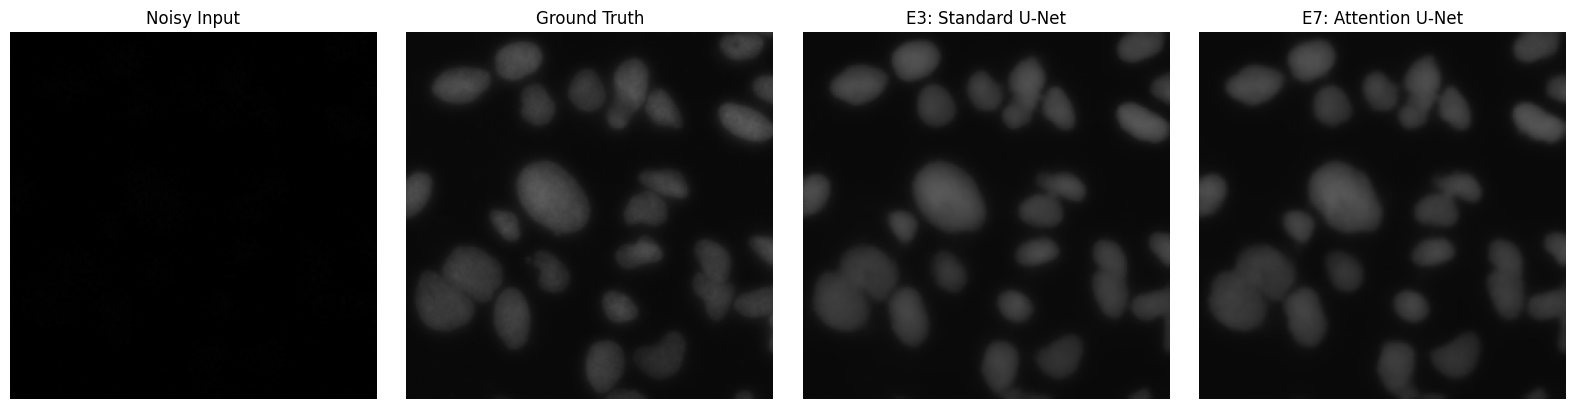

In [34]:
# E3 vs E7: Visual comparison
model_e3 = UNet().to(device)
model_e3.load_state_dict(torch.load("/content/best_unet.pth", map_location=device))
model_e3.eval()

model_e7.load_state_dict(torch.load("/content/best_unet_attention.pth", map_location=device))
model_e7.eval()

noisy, target = next(iter(test_loader))
noisy, target = noisy[:1].to(device), target[:1].to(device)

with torch.no_grad():
    pred_e3 = model_e3(noisy)
    pred_e7 = model_e7(noisy)

images = [
    ("Noisy Input", noisy[0, 0].cpu().numpy()),
    ("Ground Truth", target[0, 0].cpu().numpy()),
    ("E3: Standard U-Net", pred_e3[0, 0].cpu().numpy()),
    ("E7: Attention U-Net", pred_e7[0, 0].cpu().numpy())
]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, (title, img) in zip(axes, images):
    ax.imshow(img, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

## E7: Attention U-Net — Test Evaluation

Evaluate Attention U-Net against the standard U-Net using the same test dataset.

Metrics:
- PSNR: Overall reconstruction quality.
- SSIM: Structural similarity.
- Foreground PSNR: Reconstruction quality in biologically relevant foreground regions.
- Edge MAE: Difference in image gradients.

The objective is to determine whether attention improves denoising and preserves biological structures.

In [35]:
# E3 vs E7: Quantitative comparison
import numpy as np
import pandas as pd
import torch
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from skimage.filters import threshold_otsu, sobel

# Load best checkpoints
model_e3 = UNet().to(device)
model_e3.load_state_dict(torch.load("/content/best_unet.pth", map_location=device))
model_e3.eval()

model_e7 = AttentionUNet().to(device)
model_e7.load_state_dict(torch.load("/content/best_unet_attention.pth", map_location=device))
model_e7.eval()

results = {"E3": [], "E7": []}

for noisy, target in test_loader:
    noisy, target = noisy.to(device), target.to(device)

    with torch.no_grad():
        pred_e3 = model_e3(noisy).clamp(0, 1)
        pred_e7 = model_e7(noisy).clamp(0, 1)

    for name, prediction in [("E3", pred_e3), ("E7", pred_e7)]:
        for i in range(target.shape[0]):
            gt = target[i, 0].cpu().numpy()
            pred = prediction[i, 0].cpu().numpy()

            # Overall metrics
            psnr = peak_signal_noise_ratio(gt, pred, data_range=1)
            ssim = structural_similarity(gt, pred, data_range=1)

            # Foreground PSNR using GT-derived Otsu mask
            mask = gt > threshold_otsu(gt)
            fg_mse = np.mean((gt[mask] - pred[mask]) ** 2)
            fg_psnr = 10 * np.log10(1 / max(fg_mse, 1e-12))

            # Consistent Sobel edge MAE
            edge_mae = np.mean(np.abs(sobel(gt) - sobel(pred)))

            results[name].append([psnr, ssim, fg_psnr, edge_mae])

# Average test metrics
metrics = ["PSNR", "SSIM", "Foreground PSNR", "Edge MAE"]

comparison = pd.DataFrame({
    name: np.mean(values, axis=0)
    for name, values in results.items()
}, index=metrics)

print(comparison.round(5))

                       E3        E7
PSNR             39.16997  39.01370
SSIM              0.97053   0.96983
Foreground PSNR  33.13745  32.94136
Edge MAE          0.00306   0.00311


## E8: Swin-UNet

This experiment introduces a Transformer-based U-Net architecture
using a Swin Transformer encoder and a convolutional decoder.

The Swin Transformer uses shifted-window self-attention to learn
spatial relationships at different image scales.

**Objective:** Improve microscopy image denoising while preserving
fine biological structures.

- Dataset: Same AI4Life dataset and split
- Input: Noisy image
- Encoder: Swin Transformer Tiny
- Decoder: U-Net-style convolutional decoder
- Loss: L1
- Optimizer: Adam
- Epochs: 30

Compare against E3 Standard U-Net and E7 Attention U-Net.

In [36]:
# E8: Swin-UNet
!pip -q install timm

import torch
import torch.nn as nn
import torch.nn.functional as F
import timm

# Decoder block
class SwinDecoderBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class SwinUNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder = timm.create_model(
            "swin_tiny_patch4_window7_224",
            pretrained=False,
            in_chans=1,
            img_size=256,
            features_only=True,
            out_indices=(0, 1, 2, 3)
        )

        # Swin Tiny feature channels: 96, 192, 384, 768
        self.dec3 = SwinDecoderBlock(768 + 384, 384)
        self.dec2 = SwinDecoderBlock(384 + 192, 192)
        self.dec1 = SwinDecoderBlock(192 + 96, 96)

        self.final = nn.Sequential(
            SwinDecoderBlock(96, 32),
            nn.Conv2d(32, 1, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        input_size = x.shape[-2:]

        features = self.encoder(x)

        # Ensure feature maps are in NCHW format
        channels = [96, 192, 384, 768]
        features = [
            f if f.shape[1] == c else f.permute(0, 3, 1, 2)
            for f, c in zip(features, channels)
        ]

        f1, f2, f3, f4 = features

        # Decoder with skip connections
        d3 = F.interpolate(f4, size=f3.shape[-2:], mode="bilinear",
                           align_corners=False)
        d3 = self.dec3(torch.cat([d3, f3], dim=1))

        d2 = F.interpolate(d3, size=f2.shape[-2:], mode="bilinear",
                           align_corners=False)
        d2 = self.dec2(torch.cat([d2, f2], dim=1))

        d1 = F.interpolate(d2, size=f1.shape[-2:], mode="bilinear",
                           align_corners=False)
        d1 = self.dec1(torch.cat([d1, f1], dim=1))

        output = F.interpolate(d1, size=input_size, mode="bilinear",
                               align_corners=False)

        return self.final(output)


# Initialize model
model_e8 = SwinUNet().to(device)

print("Parameters:", sum(p.numel() for p in model_e8.parameters()))

optimizer = torch.optim.Adam(model_e8.parameters(), lr=1e-4)
criterion = nn.L1Loss()

best_val_loss = float("inf")
epochs = 30

for epoch in range(epochs):
    model_e8.train()
    train_loss = 0

    for noisy, target in train_loader:
        noisy, target = noisy.to(device), target.to(device)

        optimizer.zero_grad()
        output = model_e8(noisy)
        loss = criterion(output, target)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    model_e8.eval()
    val_loss = 0

    with torch.no_grad():
        for noisy, target in val_loader:
            noisy, target = noisy.to(device), target.to(device)
            output = model_e8(noisy)
            val_loss += criterion(output, target).item()

    train_loss /= len(train_loader)
    val_loss /= len(val_loader)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model_e8.state_dict(), "/content/best_swin_unet.pth")

    print(
        f"Epoch {epoch+1:02d}/{epochs} | "
        f"Train: {train_loss:.6f} | "
        f"Val: {val_loss:.6f}"
    )

print("Best validation loss:", best_val_loss)

Parameters: 34523163
Epoch 01/30 | Train: 0.303661 | Val: 0.252251
Epoch 02/30 | Train: 0.231624 | Val: 0.201683
Epoch 03/30 | Train: 0.176159 | Val: 0.149752
Epoch 04/30 | Train: 0.130229 | Val: 0.121249
Epoch 05/30 | Train: 0.093337 | Val: 0.080267
Epoch 06/30 | Train: 0.063107 | Val: 0.031268
Epoch 07/30 | Train: 0.042196 | Val: 0.067379
Epoch 08/30 | Train: 0.027352 | Val: 0.033637
Epoch 09/30 | Train: 0.017130 | Val: 0.018485
Epoch 10/30 | Train: 0.012034 | Val: 0.007696
Epoch 11/30 | Train: 0.009122 | Val: 0.008019
Epoch 12/30 | Train: 0.008681 | Val: 0.013436
Epoch 13/30 | Train: 0.008083 | Val: 0.007120
Epoch 14/30 | Train: 0.007996 | Val: 0.011556
Epoch 15/30 | Train: 0.007672 | Val: 0.006919
Epoch 16/30 | Train: 0.007469 | Val: 0.008251
Epoch 17/30 | Train: 0.007506 | Val: 0.008542
Epoch 18/30 | Train: 0.007204 | Val: 0.006924
Epoch 19/30 | Train: 0.006979 | Val: 0.021436
Epoch 20/30 | Train: 0.006914 | Val: 0.006505
Epoch 21/30 | Train: 0.006772 | Val: 0.007443
Epoch 22/30 |

## E8: Swin-based U-Net — Test Evaluation

Evaluate the Swin-based U-Net against E3 and E7.

Metrics:
- PSNR
- SSIM
- Foreground PSNR
- Edge MAE

All models use the same test dataset and evaluation procedure.

In [37]:
# E3 vs E7 vs E8: Test evaluation
import numpy as np
import pandas as pd
import torch
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from skimage.filters import threshold_otsu, sobel

models = {
    "E3": UNet().to(device),
    "E7": AttentionUNet().to(device),
    "E8": SwinUNet().to(device)
}

checkpoints = {
    "E3": "/content/best_unet.pth",
    "E7": "/content/best_unet_attention.pth",
    "E8": "/content/best_swin_unet.pth"
}

for name, model in models.items():
    model.load_state_dict(torch.load(checkpoints[name], map_location=device))
    model.eval()

results = {name: [] for name in models}

for noisy, target in test_loader:
    noisy, target = noisy.to(device), target.to(device)

    with torch.no_grad():
        predictions = {
            name: model(noisy).clamp(0, 1)
            for name, model in models.items()
        }

    for name, prediction in predictions.items():
        for i in range(target.shape[0]):
            gt = target[i, 0].cpu().numpy()
            pred = prediction[i, 0].cpu().numpy()

            psnr = peak_signal_noise_ratio(gt, pred, data_range=1)
            ssim = structural_similarity(gt, pred, data_range=1)

            mask = gt > threshold_otsu(gt)
            fg_mse = np.mean((gt[mask] - pred[mask]) ** 2)
            fg_psnr = 10 * np.log10(1 / max(fg_mse, 1e-12))

            edge_mae = np.mean(np.abs(sobel(gt) - sobel(pred)))

            results[name].append([psnr, ssim, fg_psnr, edge_mae])

comparison = pd.DataFrame(
    {name: np.mean(values, axis=0) for name, values in results.items()},
    index=["PSNR", "SSIM", "Foreground PSNR", "Edge MAE"]
)

print(comparison.round(5))

                       E3        E7        E8
PSNR             39.16997  39.01370  39.10660
SSIM              0.97053   0.96983   0.97020
Foreground PSNR  33.13745  32.94136  33.34398
Edge MAE          0.00306   0.00311   0.00312


## E8: Swin-based U-Net — Visual Comparison

Compare the reconstruction quality of the standard U-Net (E3)
and Swin-based U-Net (E8).

Focus on:
- Nuclei visibility
- Fine structural details
- Noise removal
- Preservation of boundaries

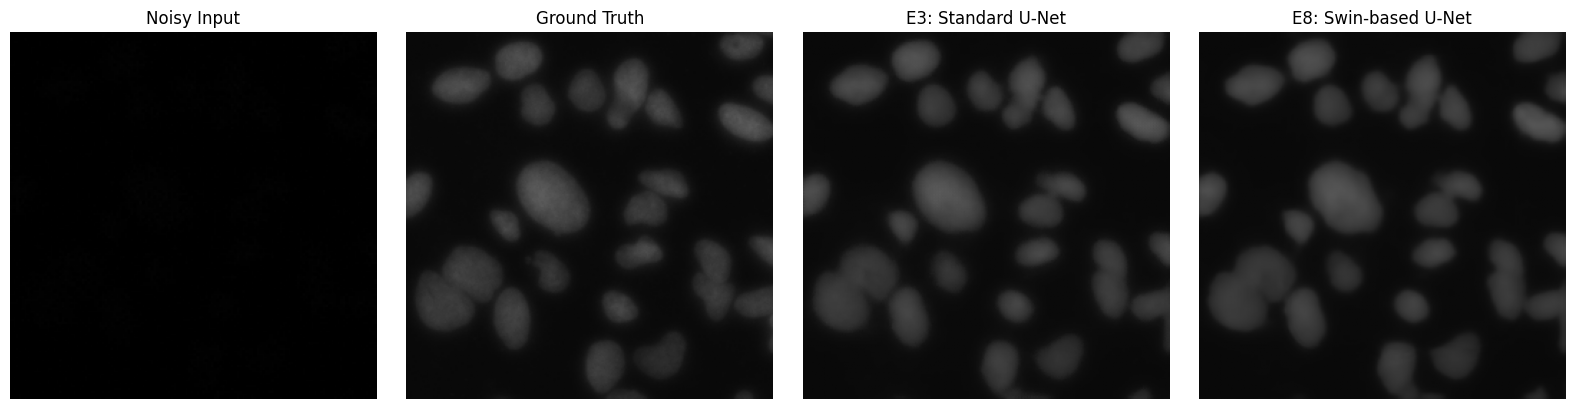

In [38]:
# E3 vs E8 visual comparison

noisy, target = next(iter(test_loader))
noisy, target = noisy[:1].to(device), target[:1].to(device)

with torch.no_grad():
    pred_e3 = models["E3"](noisy).clamp(0, 1)
    pred_e8 = models["E8"](noisy).clamp(0, 1)

images = [
    ("Noisy Input", noisy[0, 0].cpu().numpy()),
    ("Ground Truth", target[0, 0].cpu().numpy()),
    ("E3: Standard U-Net", pred_e3[0, 0].cpu().numpy()),
    ("E8: Swin-based U-Net", pred_e8[0, 0].cpu().numpy())
]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, (title, img) in zip(axes, images):
    ax.imshow(img, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()